# SNR study of the fast-photometry test-star observations

Measured signal-to-noise ratio of every test-star observation, obtained in the
different ways explored in the old `check_fast_photometry_data.ipynb`, compared to the
theoretical SNR of `Instrument.noise_budget`, together with everything about each
observation that the binary files do not record and that could explain the disparity.

The pipeline itself (conditions, NSB, measured and theoretical SNR) lives in
`kbo_occultation.analysis.snr` and is what `kbo-night snr` runs; this notebook calls it
and adds the diagnostics.

**Sources**
- `kbo_occultation/data/observations/observation_log.yaml`: stars, magnitudes (SIMBAD B and V), coordinates, good-time windows, faulty mirrors, eLog notes. *Edit it there, not here.*
- `kbo_occultation/data/observations/conditions/<night>/`: weather, pyrometer, AMC, starguider and CC pointing, extracted from the MAGIC CC `.rep` files by `kbo-night prepare`.
- `DCs/<night>/dc_report.pkl`: slow DC reports (needs `magic_spysii` to unpickle).
- Zd, airmass and moon are computed with astropy from the coordinates and the run times, and cross-checked against the CC reports.

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astropy.time import Time

from kbo_occultation import config
from kbo_occultation.observations.log import load_observation_log, nights_table, observations_table, validate
from kbo_occultation.observations.cc_reports import load_conditions, pointing_conditions, conditions_table
from kbo_occultation.observations.dc_combine import load_dc_series, combine_lightcurve_with_dc
from kbo_occultation.simulation.detectability import bin_average
from kbo_occultation.analysis.snr import (N_BINS, DETREND_WINDOW_S, DC_CUT_HZ, load_lightcurves, nsb_table,
                                          measured_snr_table, theoretical_snr_table, plot_snr_vs_magnitude)
from kbo_occultation.analysis.snr_measurement import (good_time_lightcurve, detrended_snr, band_noise_rms,
                                                      noise_vs_bin_size, frame_noise, variance_estimator_floor)

warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 40)
pd.set_option("display.precision", 3)

log = load_observation_log()
NIGHTS = log.select()   # skips nights/observations with `exclude:` in the log; log.select(include_excluded=True) for all
NIGHT_COLORS = dict(zip(log.nights, ["tab:blue", "tab:red", "tab:green"]))
TELESCOPES = {ch: config.ORM_ARRAY.by_channel(ch) for ch in "ABC"}
MARKERS = {"MAGIC-1": "s", "MAGIC-2": "o", "LST-1": "^"}

## 1. Observation log

In [2]:
nights_table(log)

,telescopes,optical_filter,n_stars,dark_run,cc_reports,faulty_panels,elog_notes,exclude
night,,,,,,,,
2025-12-16,MAGIC-2,none,5,dark,m2,"{""m2"": 1}",{'m2': 10.07},None
2026-03-08,"MAGIC-2, LST-1, MAGIC-1",none,3,None,"m1, m2","{""m1"": 35, ""m2"": 19, ""lst1"": null}","{'m1': 9.45, 'm2': 9.02}",None
2026-08-19,"MAGIC-2, LST-1, MAGIC-1",none,4,DarkPatch54,"m1, m2","{""m1"": 11, ""m2"": 2, ""lst1"": null}","{'m1': 11.15, 'm2': 9.71, 'lst1': 46.69}",None


In [3]:
observations_table(log)

type   spectral_type  mag_B  mag_V   ra_deg  dec_deg                start_utc                 stop_utc good_time_s                                              notes exclude
night      observation                                                                                                                                                                               
2025-12-16 HD-4335      star  B9.5IIIp(HgMn)  5.954  6.024   11.545   44.861  2025-12-16T21:23:00.272  2025-12-16T21:31:11.437  [230, 280]                                               None    None
           HD-8837      star            B9IV  6.553  6.587   21.945   40.336  2025-12-16T22:08:19.836  2025-12-16T22:16:06.995    [18, 48]                                               None    None
           HD-22353     star              B9  7.038  7.008   54.347   40.090  2025-12-16T22:23:28.140  2025-12-16T22:29:12.257  [200, 230]                                               None    None
           HD-17316     star              B9  7.530  7.420   42.059   43.623  2025-12-16T22:33:24.927  2025-12-16T22:40:31.075  [300, 380]                                               None    None
           HD-20920     star              B8  7.960  8.030   50.981   41.337  2025-12-16T23:05:22.560  2025-12-16T23:11:59.695  [100, 250]                                               None    None
           dark         dark            None    NaN    NaN      NaN      NaN  2025-12-16T23:15:18.364  2025-12-16T23:22:06.497        None  Dark run used as the NSB reference for the night.    None
2026-03-08 HD-40626     star          B9.5IV  5.998  6.040   90.703   49.906  2026-03-08T22:10:15.176  2026-03-08T22:14:16.258  [120, 163]                                               None    None
           HD-45563     star            B9IV  6.403  6.450   97.070    1.913  2026-03-08T22:25:51.236  2026-03-08T22:29:48.316  [153, 205]                                               None    None
           HD-46016     star              B8  6.970  7.000   98.290   46.476  2026-03-08T22:34:12.372  2026-03-08T22:38:49.466  [101, 166]                                               None    None
2026-08-19 DarkPatch54  dark            None    NaN    NaN  276.980   28.880  2026-08-20T00:51:52.940  2026-08-20T00:57:03.035        None             Dark patch taken just before HD170263.    None
           HD170263     star              B8  8.620  8.620  276.823   28.929  2026-08-20T00:59:06.100  2026-08-20T01:05:01.221    [3, 350]                                               None    None
           HD176914     star              B5  6.927  7.034  285.325   28.412  2026-08-20T01:11:08.220  2026-08-20T01:16:05.320   [68, 115]                                               None    None
           DarkPatch53  dark            None    NaN    NaN  285.150   28.270  2026-08-20T01:18:02.960  2026-08-20T01:23:03.061        None                                               None    None
           HD196243     star              B5  7.480  7.590  308.781   30.253  2026-08-20T01:27:12.868  2026-08-20T01:32:07.963  [215, 290]                                               None    None
           HD199102     star             B9V  8.000  8.020  313.486   29.500  2026-08-20T01:35:09.780  2026-08-20T01:40:05.880   [52, 185]                                               None    None

Faulty mirrors and eLog notes per night (as typed in the YAML), and everything still missing (`validate`, the same list `kbo-night prepare` prints), i.e. things to fill in from the eLog / shift reports:

In [4]:
for night in NIGHTS:
    print(f"── {night.name}")
    print(f"   faulty mirrors: {night.faulty_mirrors}")
    print(f"   eLog: {night.elog_notes}")
    for problem in validate(night):
        print(f"   missing: {problem}")

── 2025-12-16
   faulty mirrors: {'m2': 1}
   eLog: {'m2': 10.07}
   missing: dark: null ra_deg, dec_deg
── 2026-03-08
   faulty mirrors: {'m1': 35, 'm2': 19, 'lst1': None}
   eLog: {'m1': 9.45, 'm2': 9.02}
── 2026-08-19
   faulty mirrors: {'m1': 11, 'm2': 2, 'lst1': None}
   eLog: {'m1': 11.15, 'm2': 9.71, 'lst1': 46.69}


## 2. Observing conditions

Per observation: pointing and moon (astropy), and the CC-report weather, pyrometer, starguider and AMC panel status averaged over the run. The CC-report Zd is shown as a cross-check of the computed one (CC wrote `00.00` all through 2025-12-16, so it is missing there). Weather and the pyrometer are site-wide; AMC is per telescope. A night's YAML `manual_conditions` (optional) are added for anything the reports don't cover.

In [5]:
conditions = conditions_table(log)
conditions

type  zd_mean_deg  zd_min_deg  zd_max_deg  airmass_mean  moon_alt_deg  moon_illumination  moon_separation_deg    cc_source  cc_zd_mean_deg  cc_zd_min_deg  cc_zd_max_deg cc_moon_flag  temperature_C  humidity_pct  \
night      observation                                                                                                                                                                                                                       
2025-12-16 HD-4335      star       21.480      20.956      22.014         1.075       -73.568              0.091              143.899      HD-4335             NaN            NaN            NaN      No_Moon          3.434        70.599   
           HD-8837      star       19.235      18.607      19.870         1.059       -81.717              0.089              152.514      HD-8837             NaN            NaN            NaN      No_Moon          4.004        61.077   
           HD-22353     star       14.197      13.852      14.553         1.032       -83.354              0.088              161.281     HD-22353             NaN            NaN            NaN      No_Moon          4.013        62.078   
           HD-17316     star       15.440      15.277      15.622         1.037       -83.834              0.087              158.504     HD-17316             NaN            NaN            NaN      No_Moon          4.457        56.514   
           HD-20920     star       13.030      12.884      13.196         1.026       -80.987              0.086              161.008     HD-20920             NaN            NaN            NaN      No_Moon          4.286        62.820   
           dark         dark          NaN         NaN         NaN           NaN           NaN                NaN                  NaN         dark             NaN            NaN            NaN      No_Moon          4.342        61.962   
2026-03-08 HD-40626     star       31.339      31.061      31.618         1.171       -24.758              0.720              137.341     HD-40626          31.322          31.06          31.59      No_Moon          4.710        24.175   
           HD-45563     star       38.058      37.725      38.392         1.270       -21.599              0.719              128.009     HD-45563          38.050          37.73          38.37      No_Moon          4.893        24.532   
           HD-46016     star       28.783      28.431      29.137         1.141       -19.845              0.718              133.765     HD-46016          28.776          28.42          29.12      No_Moon          4.913        24.300   
2026-08-19 DarkPatch54  dark       40.777      40.221      41.332         1.321       -13.657              0.487               69.312  DarkPatch54          40.757          40.22          41.29      No_Moon         13.612        47.472   
           HD170263     star       42.532      41.897      43.167         1.357       -15.164              0.487               69.214     HD170263          42.512          41.89          43.13      No_Moon         13.604        47.912   
           HD176914     star       37.813      37.277      38.348         1.266       -17.468              0.488               74.238     HD176914          37.802          37.30          38.31      No_Moon         13.594        48.867   
           DarkPatch53  dark       39.491      38.951      40.031         1.296       -18.858              0.488               73.988  DarkPatch53          39.476          38.95          40.00      No_Moon         13.492        49.735   
           HD196243     star       20.791      20.260      21.323         1.070       -20.694              0.489               92.129     HD196243          20.790          20.27          21.31      No_Moon         13.360        50.222   
           HD199102     star       18.466      17.929      19.004         1.054       -22.300              0.490               95.387     HD199102          18.457          17.96          18.96      No_Moon         13

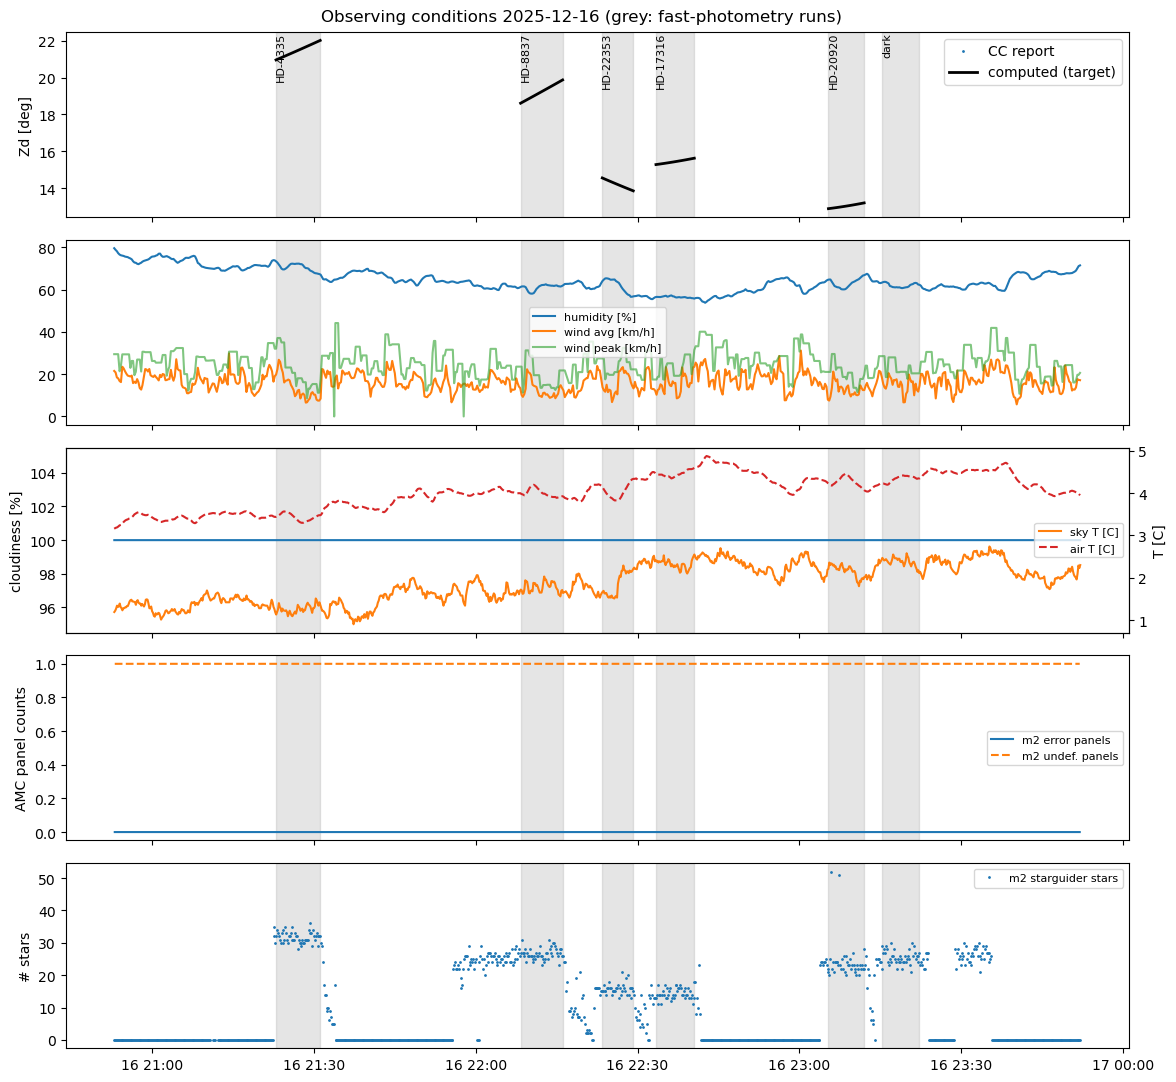

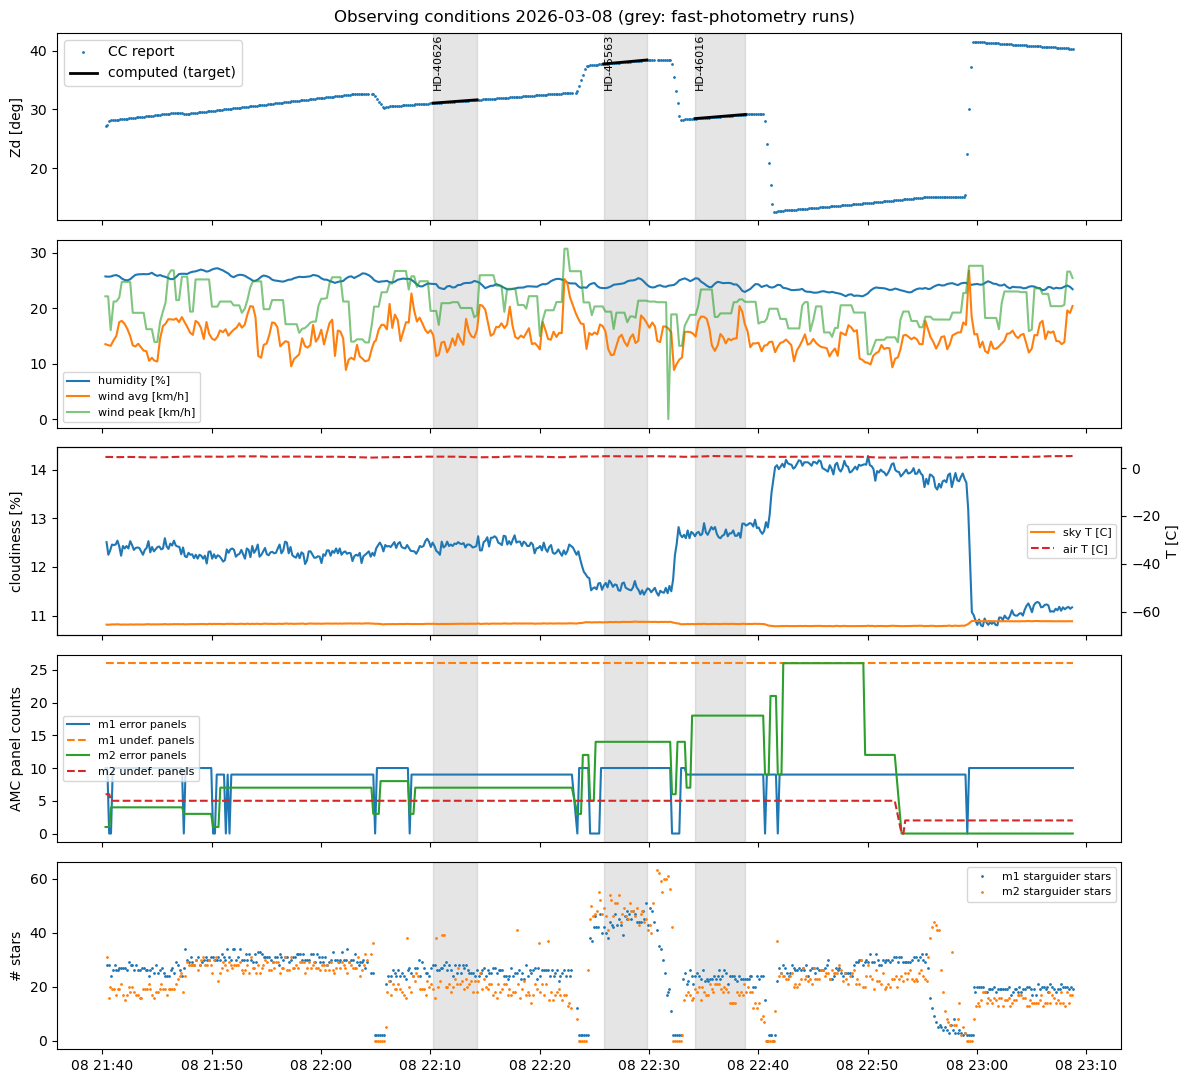

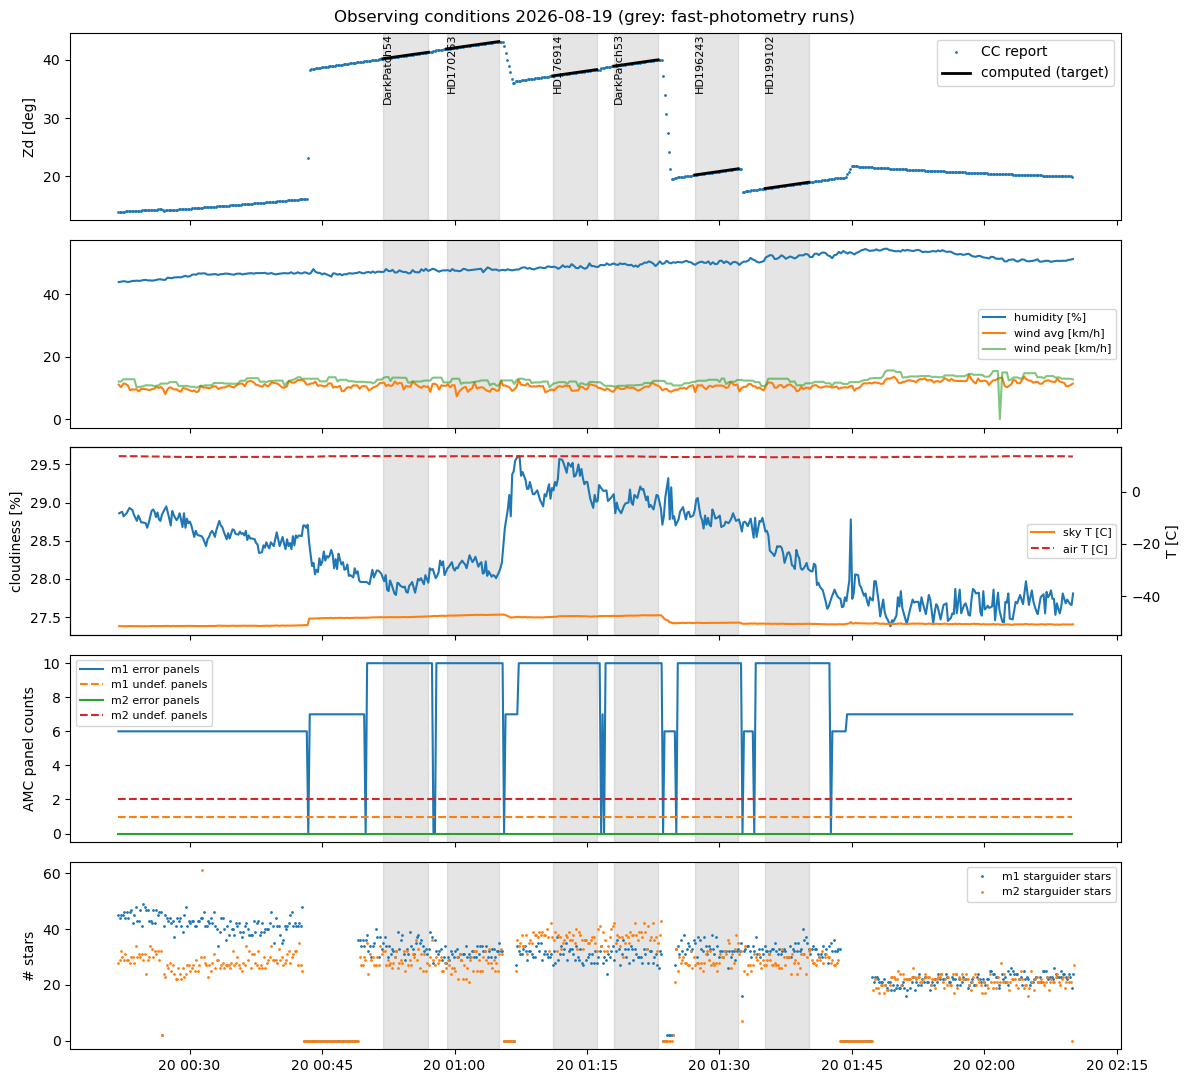

In [6]:
for night in NIGHTS:
    cond = load_conditions(night.conditions_dir) if night.conditions_dir else {}
    if not cond:
        continue
    site = cond.get("m2") or next(iter(cond.values()))
    spans = {o.name: o.time_span() for o in night.observations.values()}
    fig, axes = plt.subplots(5, 1, figsize=(12, 11), sharex=True)
    to_dt = lambda t: Time(t, format="unix").datetime
    cc = site["cc"]
    axes[0].plot(to_dt(cc.time), cc.zd_deg, ".", ms=2, label="CC Zd")
    for name, (t0, t1) in spans.items():
        obs = night.observations[name]
        if obs.ra_deg is not None:
            tt = np.linspace(t0, t1, 10)
            zd = [pointing_conditions(obs.ra_deg, obs.dec_deg, t, t + 1, 2)["zd_mean_deg"] for t in tt]
            axes[0].plot(to_dt(tt), zd, "k-", lw=2)
    axes[0].set_ylabel("Zd [deg]"); axes[0].legend(["CC report", "computed (target)"])
    w = site["weather"]
    axes[1].plot(to_dt(w.time), w.humidity_pct, label="humidity [%]")
    axes[1].plot(to_dt(w.time), w.wind_avg_kmh, label="wind avg [km/h]")
    axes[1].plot(to_dt(w.time), w.wind_peak_kmh, label="wind peak [km/h]", alpha=0.6)
    axes[1].legend(fontsize=8)
    p = site["pyro"]
    axes[2].plot(to_dt(p.time), p.cloudiness_pct, label="cloudiness [%]")
    ax2 = axes[2].twinx()
    ax2.plot(to_dt(p.time), p.sky_temperature_K - 273.15, color="tab:orange", label="sky T [C]")
    ax2.plot(to_dt(w.time), w.temperature_C, color="tab:red", ls="--", label="air T [C]")
    axes[2].set_ylabel("cloudiness [%]"); ax2.set_ylabel("T [C]"); ax2.legend(fontsize=8, loc="center right")
    for tel, reports in cond.items():
        a = reports["amc"]
        axes[3].plot(to_dt(a.time), a.amc_panels_1, label=f"{tel} error panels")
        axes[3].plot(to_dt(a.time), a.amc_panels_3, ls="--", label=f"{tel} undef. panels")
    axes[3].set_ylabel("AMC panel counts"); axes[3].legend(fontsize=8)
    for tel, reports in cond.items():
        s = reports["starg"]
        axes[4].plot(to_dt(s.time), s.starg_n_stars, ".", ms=2, label=f"{tel} starguider stars")
    axes[4].set_ylabel("# stars"); axes[4].legend(fontsize=8)
    for ax in axes:
        for name, (t0, t1) in spans.items():
            ax.axvspan(*to_dt([t0, t1]), color="grey", alpha=0.2)
    for name, (t0, t1) in spans.items():
        axes[0].text(to_dt(t0), axes[0].get_ylim()[1], name, rotation=90, va="top", fontsize=8)
    fig.suptitle(f"Observing conditions {night.name} (grey: fast-photometry runs)")
    fig.tight_layout()
    plt.show()

## 3. Light curves

Outlier-cleaned variance (`.npz` caches), binned to ~1 s for display (blue, left axis), with the slow DC report of the on-target pixel over the same run (orange, right axis) where the night has one. Stars go from brightest to faintest (B), dark runs last. The shaded band is the good-time window from the log (the old notebook's `gt` dict); runs without one use the whole run.

In [7]:
lcs = load_lightcurves(log)   # (night, observation, channel) -> LightCurve


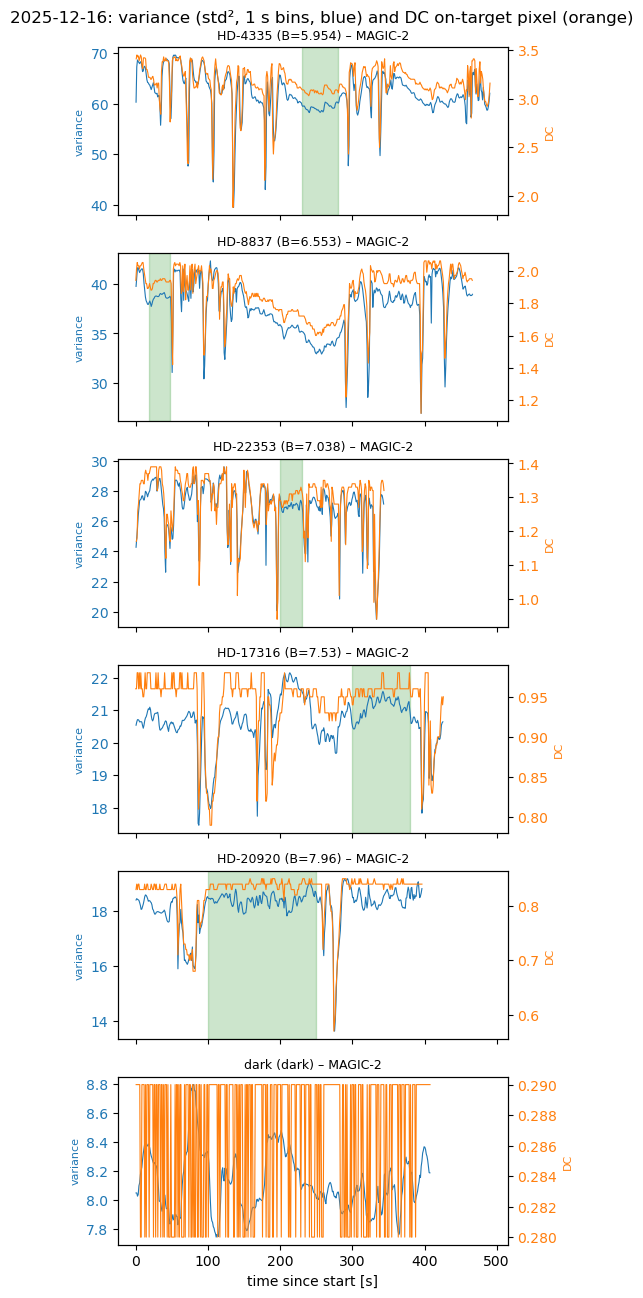

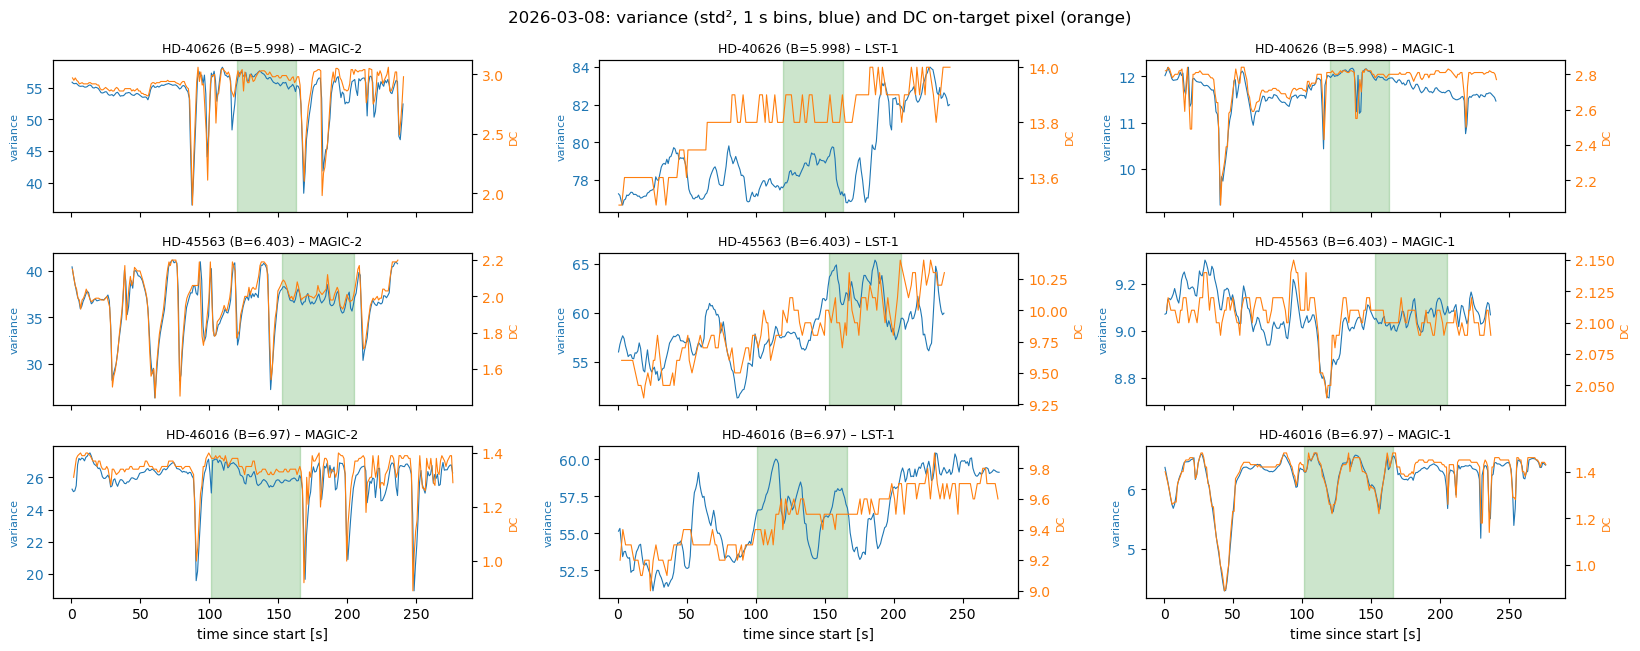

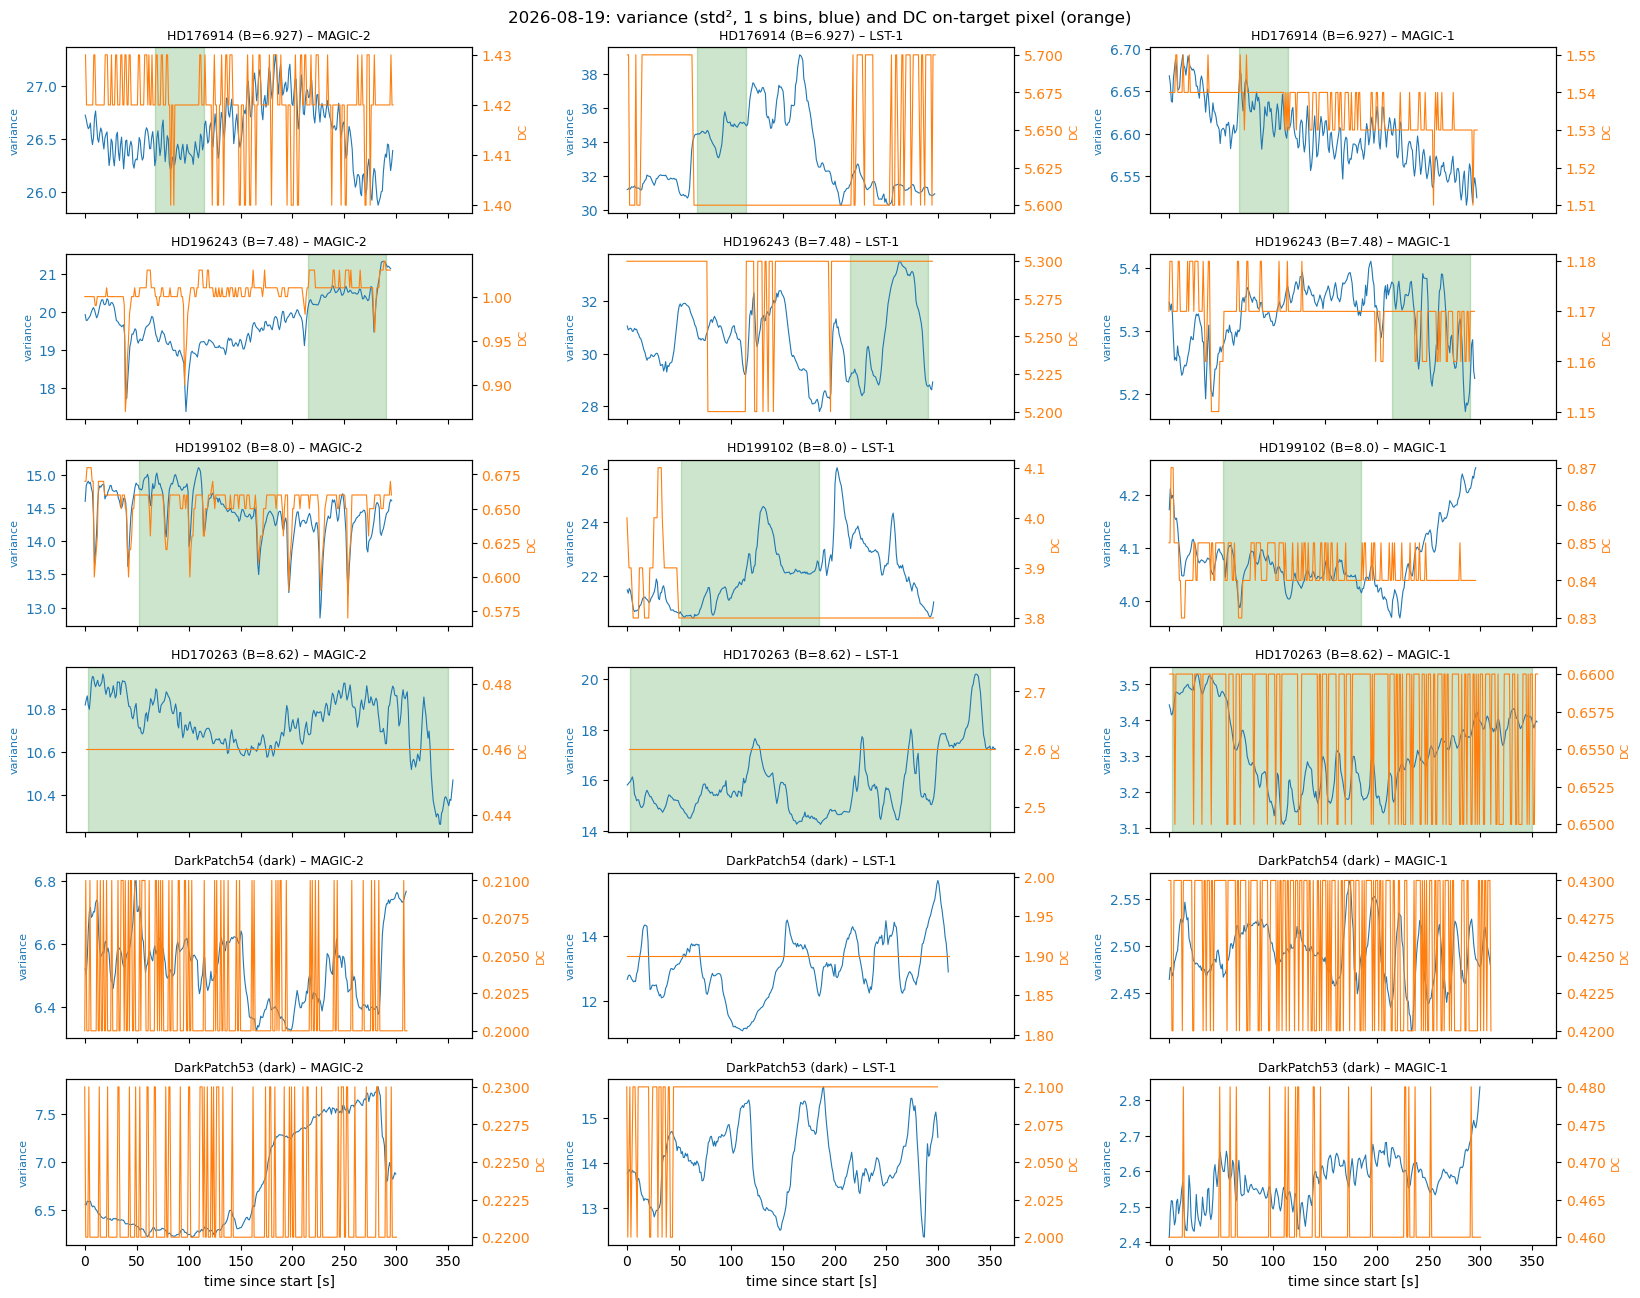

In [12]:
def plot_order(night):
    """Stars from brightest to faintest (B), then the dark runs."""
    stars = sorted(night.stars.values(), key=lambda o: (o.mag_B is None, o.mag_B or 0))
    return stars + [o for o in night.observations.values() if not o.is_star]


def night_dc(night):
    """{channel: (unix time, DC of the on-target pixel)}, loaded once per night."""
    dc = {}
    if night.dc_report and os.path.exists(night.dc_report):
        for ch in night.channels:
            try:
                dc[ch] = load_dc_series(night.dc_report, telescope=TELESCOPES[ch].dc_key)
            except ValueError:   # no DC data for that telescope
                pass
    return dc


for night in NIGHTS:
    dc = night_dc(night)
    fig, axes = plt.subplots(len(night.observations), len(night.channels), squeeze=False,
                             figsize=(5.5 * len(night.channels), 2.2 * len(night.observations)), sharex=True)
    for i, obs in enumerate(plot_order(night)):
        label = f"B={obs.mag_B}" if obs.is_star else obs.type
        for j, ch in enumerate(night.channels):
            lc = lcs[(night.name, obs.name, ch)]
            t, s, _ = bin_average(lc.time - lc.time[0], lc.signal, int(round(1 / lc.dt)))
            ax = axes[i, j]
            ax.plot(t, s, lw=0.8, color="tab:blue")
            ax.set_ylabel("variance", color="tab:blue", fontsize=8)
            ax.tick_params(axis="y", labelcolor="tab:blue")
            if ch in dc:
                t_dc, v_dc = dc[ch]
                sel = (t_dc >= lc.time[0]) & (t_dc <= lc.time[-1])
                if sel.any():
                    ax_dc = ax.twinx()
                    ax_dc.plot(t_dc[sel] - lc.time[0], v_dc[sel], lw=0.8, color="tab:orange")
                    ax_dc.set_ylabel("DC", color="tab:orange", fontsize=8)
                    ax_dc.tick_params(axis="y", labelcolor="tab:orange")
            if obs.good_time:
                ax.axvspan(*obs.good_time, color="green", alpha=0.2)
            ax.set_title(f"{obs.name} ({label}) – {TELESCOPES[ch].name}", fontsize=9)
    for ax in axes[-1]:
        ax.set_xlabel("time since start [s]")
    fig.suptitle(f"{night.name}: variance (std², 1 s bins, blue) and DC on-target pixel (orange)")
    fig.tight_layout()
    plt.savefig(f"./Original_lighcurves_and_DC_{night.name}_1s_bins.png", dpi=150)
    plt.show()

## 4. NSB (+ electronic pedestal) level

Three estimators, per observation and telescope:
- **dark**: mean of the night's dark run / dark patch in the fast signal (fast units). 2026-03-08 has no dark run.
- **dc_bkg**: the lower of the two DC background pixels during the run (DC units), converted to fast units with `dc_to_fast_scale` (mean fast / mean on-target DC).
- **dc_hist**: first peak of the on-target pixel's DC histogram over the whole report (meant for LST-1, whose background pixel reads high), converted the same way.

The default NSB used below is `dark` when available, otherwise `dc_hist` for LST-1 and `dc_bkg` for MAGIC.

In [9]:
nsb = nsb_table(log, n_bin=N_BINS[0], lcs=lcs)
nsb

dc_key  nsb_dark  nsb_dark_err  dc_scale  nsb_dc_bkg_dc  nsb_dc_hist_dc  nsb_dc_bkg  nsb_dc_hist  nsb_default nsb_source  star_mean
night      observation telescope                                                                                                                                    
2025-12-16 HD-4335     MAGIC-2       m2     8.121         0.028    19.646          0.309           0.027       6.080        0.537        8.121       dark     59.248
           HD-8837     MAGIC-2       m2     8.121         0.028    20.228          0.312           0.027       6.310        0.553        8.121       dark     38.613
           HD-22353    MAGIC-2       m2     8.121         0.028    20.838          0.387           0.027       8.070        0.570        8.121       dark     27.011
           HD-17316    MAGIC-2       m2     8.121         0.028    21.870          0.368           0.027       8.044        0.598        8.121       dark     21.107
           HD-20920    MAGIC-2       m2     8.121         0.028    22.066          0.345           0.027       7.617        0.604        8.121       dark     18.407
2026-03-08 HD-40626    MAGIC-2       m2       NaN         0.000    18.773          0.386           0.276       7.251        5.173        7.251     dc_bkg     56.330
           HD-45563    MAGIC-2       m2       NaN         0.000    18.425          0.436           0.276       8.027        5.077        8.027     dc_bkg     36.946
           HD-46016    MAGIC-2       m2       NaN         0.000    19.420          0.367           0.276       7.137        5.351        7.137     dc_bkg     26.127
           HD-40626    LST-1       lst1       NaN         0.000     5.729          8.104           2.281      46.428       13.068       13.068    dc_hist     78.649
           HD-45563    LST-1       lst1       NaN         0.000     5.919         10.979           2.281      64.987       13.502       13.502    dc_hist     61.948
           HD-46016    LST-1       lst1       NaN         0.000     5.943          7.720           2.281      45.879       13.556       13.556    dc_hist     56.799
           HD-40626    MAGIC-1       m1       NaN         0.000     4.251          0.541           0.542       2.298        2.305        2.298     dc_bkg     11.986
           HD-45563    MAGIC-1       m1       NaN         0.000     4.306          0.614           0.542       2.642        2.335        2.642     dc_bkg      9.057
           HD-46016    MAGIC-1       m1       NaN         0.000     4.475          0.530           0.542       2.374        2.426        2.374     dc_bkg      6.259
2026-08-19 HD170263    MAGIC-2       m2     6.526         0.022    23.325          0.346           0.017       8.061        0.400        6.526       dark     10.733
           HD176914    MAGIC-2       m2     6.526         0.022    18.704          0.420           0.017       7.856        0.321        6.526       dark     26.396
           HD196243    MAGIC-2       m2     6.526         0.022    19.622          0.410           0.017       8.054        0.337        6.526       dark     20.511
           HD199102    MAGIC-2       m2     6.526         0.022    22.130          0.331           0.017       7.327        0.380        6.526       dark     14.566
           HD170263    LST-1       lst1    13.029         0.078     6.098          7.413           0.135      45.209        0.820       13.029       dark     15.835
           HD176914    LST-1       lst1    13.029         0.078     5.878          8.159           0.135      47.957        0.791       13.029       dark     34.570
           HD196243    LST-1       lst1    13.029         0.078     5.772          8.321           0.135      48.027        0.776       13.029       dark     30.875
           HD199102    LST-1       lst1    13.029         0.078     5.790          7.573           0.135      43.848        0.779       13.029       dark     21.965
           HD170263    MAGIC-1       m1     2.493         0.008     5.044

### Fast + DC combined light curves

`combine_lightcurve_with_dc`: below `DC_CUT_HZ` (0.3 Hz MAGIC, 0.15 Hz LST-1; raised-cosine transition, below 0.8 x the DC Nyquist) the signal comes from the DC report, above it from the fast variance, rescaled to DC units. This is the signal behind `mean_comb`/`peak_comb` in section 5. Purple: combined, ~100 ms bins; orange: raw on-target DC samples; green: good-time window. The panel on the right is the histogram of the purple curve over the whole run; setting `HIST_GOOD_TIME_ONLY = True` restricts it to the good-time window.

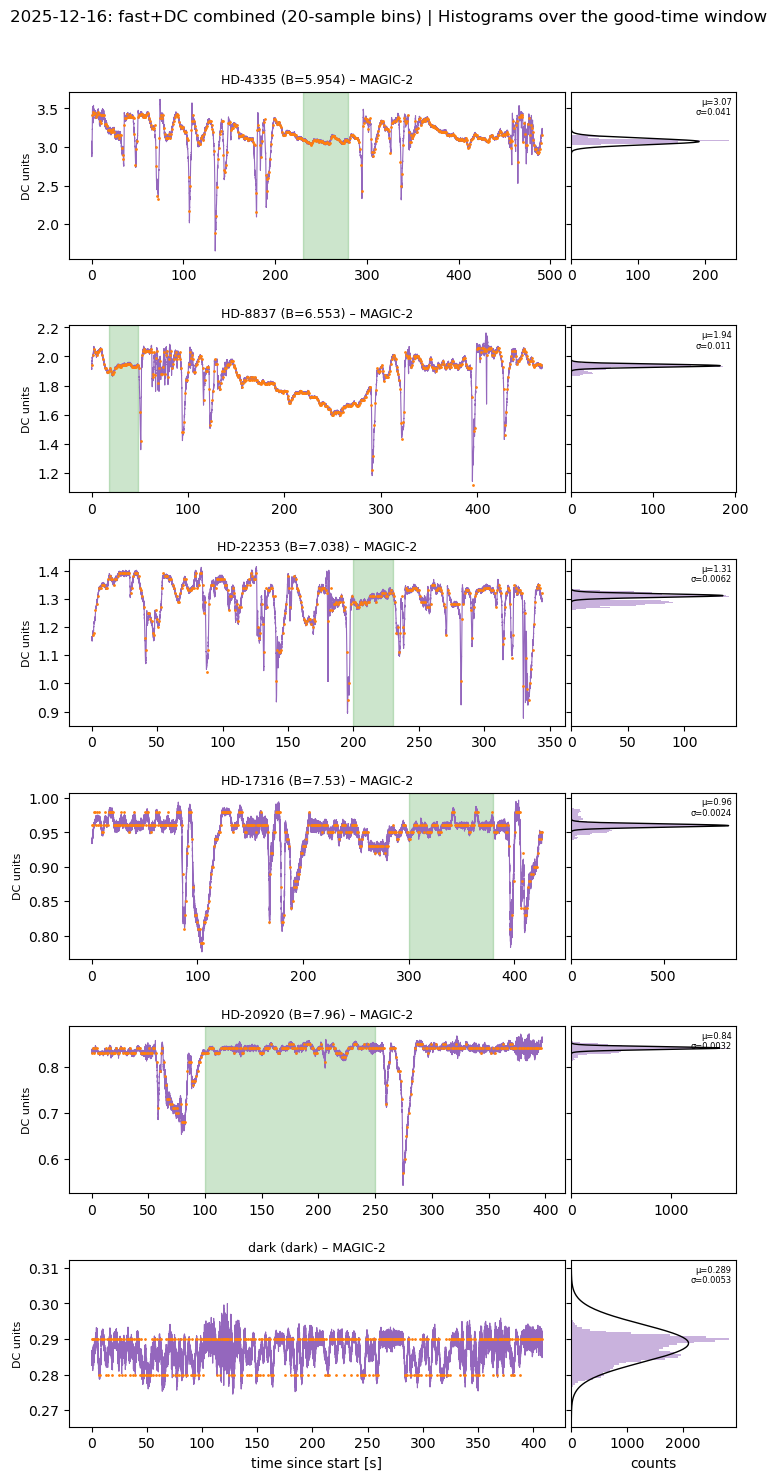

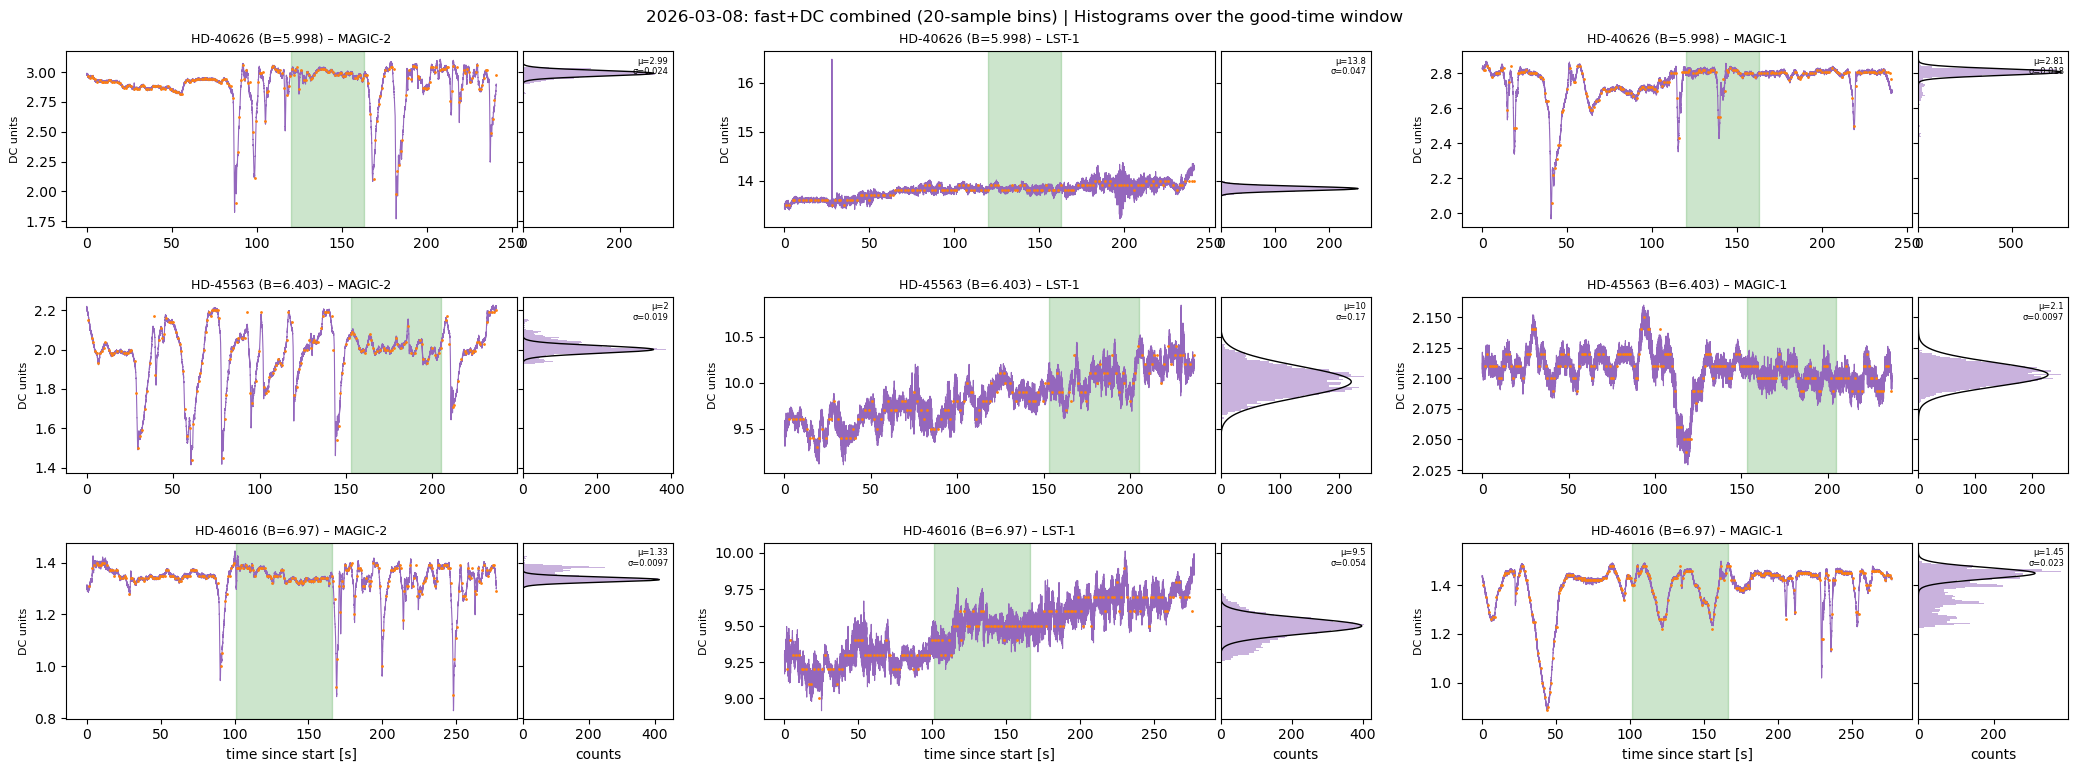

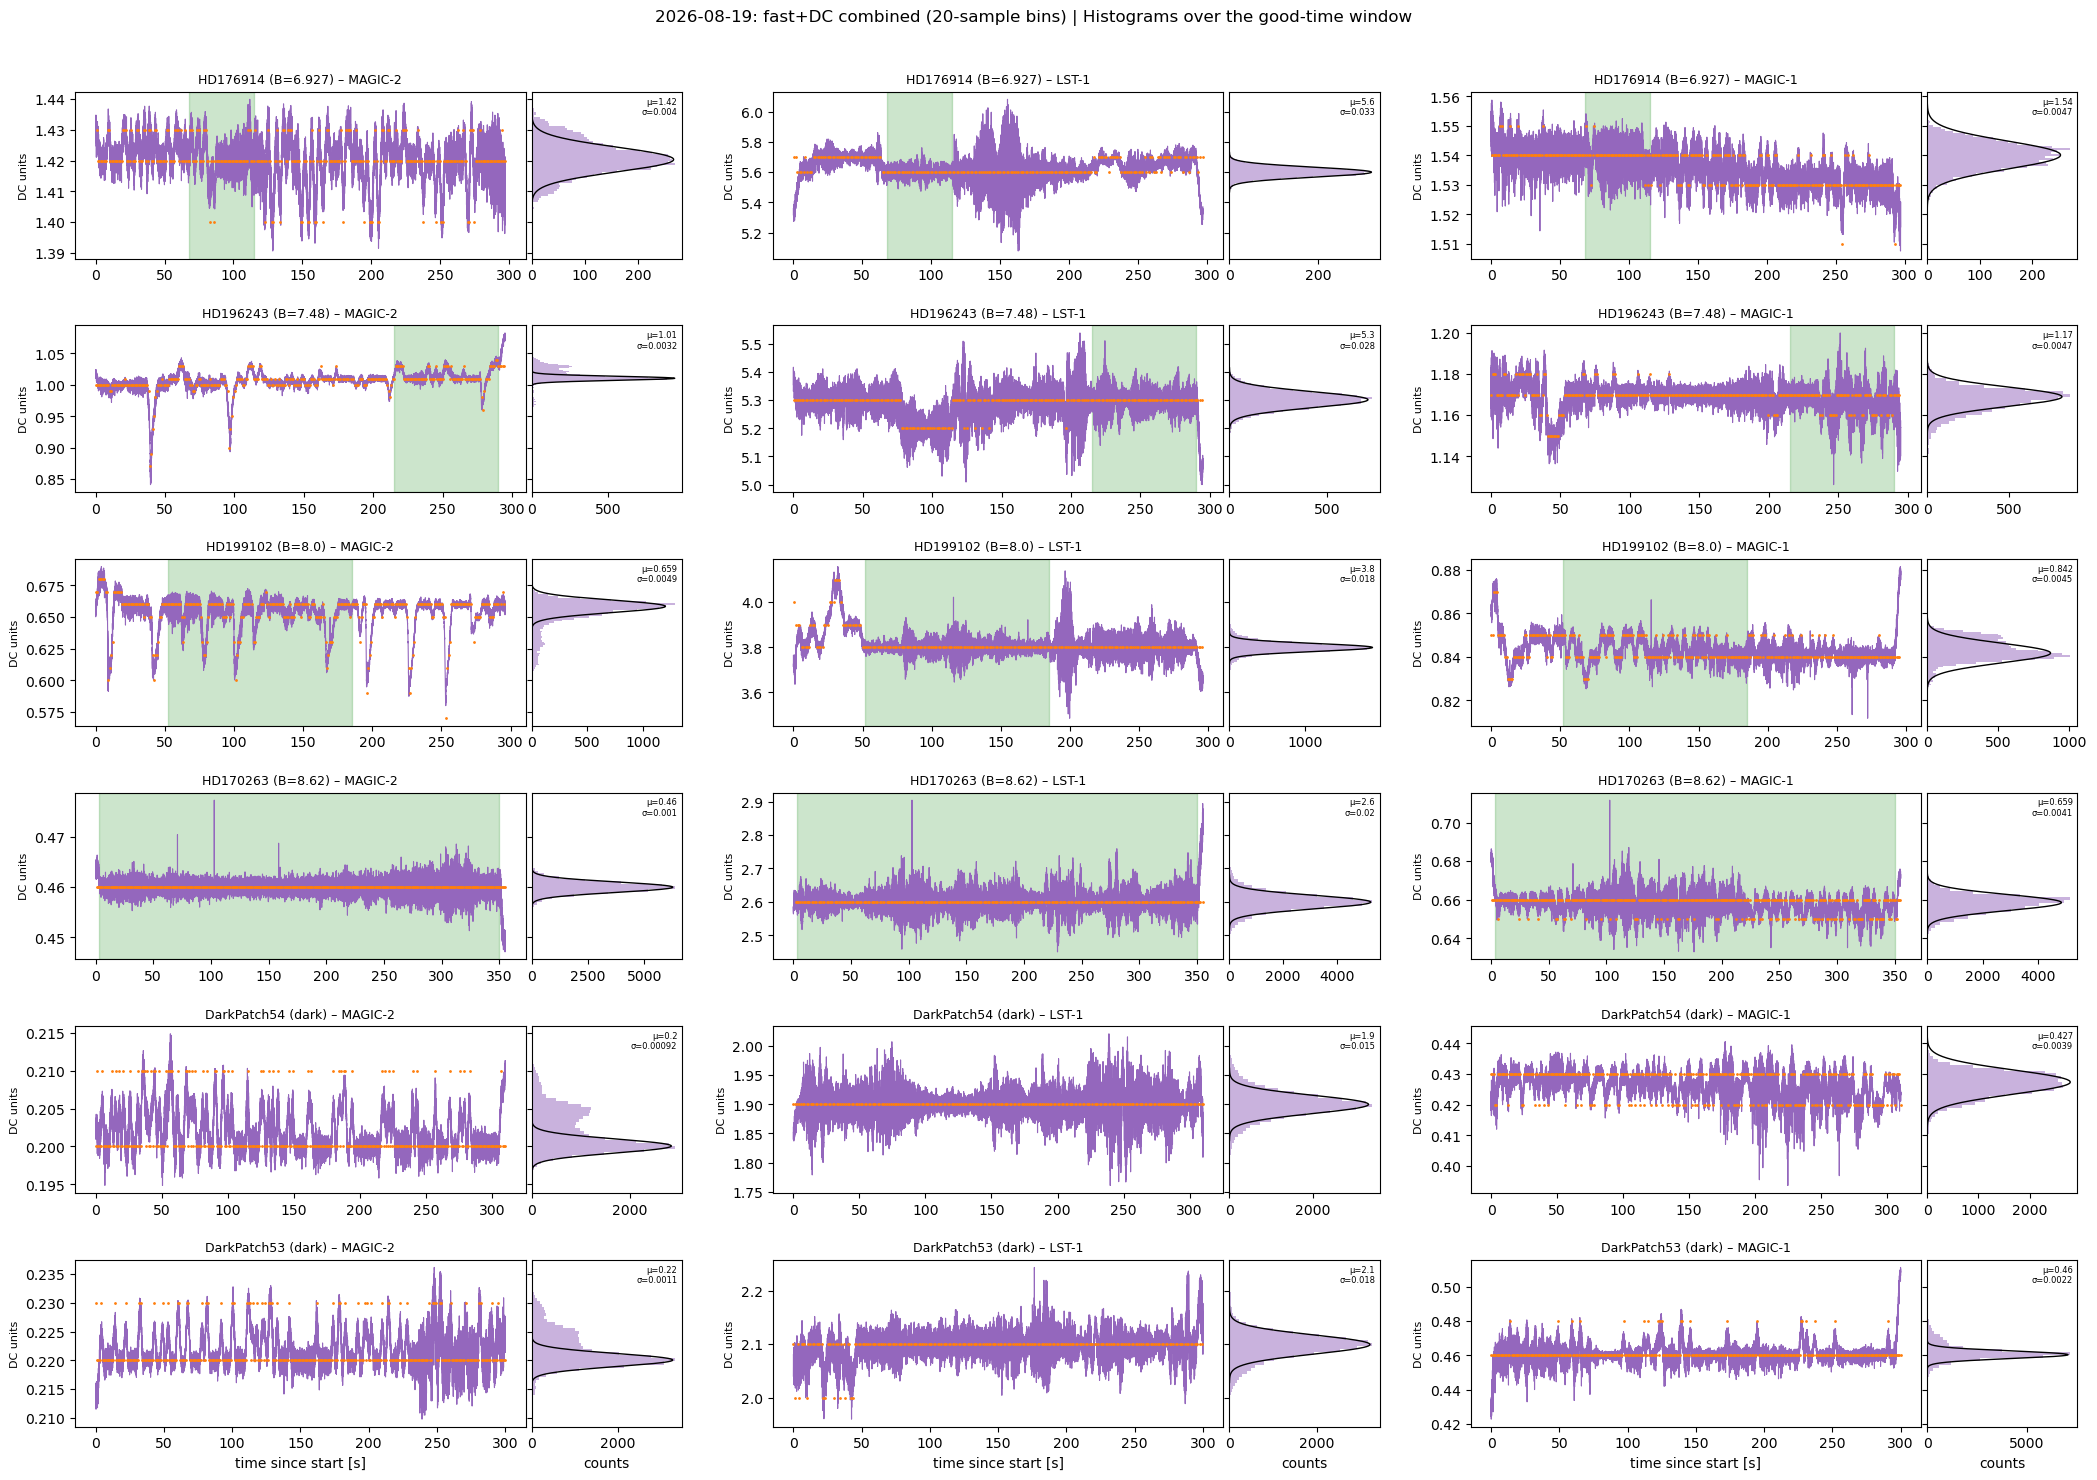

In [10]:
HIST_GOOD_TIME_ONLY = True   # True: histograms use only the good-time window
HIST_BINS = 50

from kbo_occultation.analysis.snr_measurement import gaussian_histogram_peak

for night in NIGHTS:
    dc = night_dc(night)
    if not dc:
        continue
    n_ch = len(night.channels)
    n_obs = len(night.observations)
    fig = plt.figure(figsize=(7.1 * n_ch, 2.5 * n_obs), constrained_layout=False)

    # Outer grid: rows = observations, cols = channels (wide gap between channels)
    outer = fig.add_gridspec(n_obs, n_ch, wspace=0.15, hspace=0.4)
    axes = np.empty((n_obs, n_ch), dtype=object)
    haxes = np.empty_like(axes)

    for i, obs in enumerate(plot_order(night)):
        #if "ark" in obs.name:
        #    continue
        label = f"B={obs.mag_B}" if obs.is_star else obs.type
        for j, ch in enumerate(night.channels):
            # Inner grid: curve + histogram glued together (wspace ~ 0)
            inner = outer[i, j].subgridspec(1, 2, width_ratios=[3, 1], wspace=0.02)
            #ax = axes[i, j] = fig.add_subplot(inner[0], sharex=axes[0, j] if i else None)
            ax = axes[i, j] = fig.add_subplot(inner[0])
            hax = haxes[i, j] = fig.add_subplot(inner[1], sharey=ax)
            hax.tick_params(labelleft=False)
            ax.set_title(f"{obs.name} ({label}) – {TELESCOPES[ch].name}", fontsize=9)
            lc = lcs[(night.name, obs.name, ch)]
            dc_key = TELESCOPES[ch].dc_key
            try:
                comb = combine_lightcurve_with_dc(lc, night.dc_report, DC_CUT_HZ[dc_key], telescope=dc_key)
            except (ValueError, KeyError):   # no DC for this telescope, or DC doesn't cover the run
                ax.text(0.5, 0.5, "no DC", transform=ax.transAxes, ha="center", va="center")
                hax.set_visible(False)
                continue
            t, s, _ = bin_average(comb.time - lc.time[0], comb.signal, N_BINS[1])
            ax.plot(t, s, lw=0.8, color="tab:purple")
            # Adding a horizontal line with the NSB
            #nsb_default_scaled = nsb['nsb_default'][night.name][obs.name][TELESCOPES[ch].name]/nsb['dc_scale'][night.name][obs.name][TELESCOPES[ch].name]
            #ax.axhline(nsb_default_scaled)
            t_dc, v_dc = dc[ch]
            sel = (t_dc >= lc.time[0]) & (t_dc <= lc.time[-1])
            ax.plot(t_dc[sel] - lc.time[0], v_dc[sel], ".", ms=2, color="tab:orange")
            ax.set_ylabel("DC units", fontsize=8)
            if obs.good_time:
                ax.axvspan(*obs.good_time, color="green", alpha=0.2)
            in_hist = (t >= obs.good_time[0]) & (t <= obs.good_time[1]) if HIST_GOOD_TIME_ONLY and obs.good_time else slice(None)
            counts, edges, _ = hax.hist(s[in_hist], bins=HIST_BINS, orientation="horizontal", color="tab:purple", alpha=0.5)
            mu, sig, amp = gaussian_histogram_peak(s[in_hist], HIST_BINS)   # same fit as nsb_table's NSB
            if np.isfinite(mu):
                yy = np.linspace(mu - 4 * sig, mu + 4 * sig, 200)
                hax.plot(amp * np.exp(-0.5 * ((yy - mu) / sig) ** 2), yy, color="k", lw=1)
                hax.text(0.97, 0.97, f"μ={mu:.3g}\nσ={sig:.2g}", transform=hax.transAxes, ha="right", va="top", fontsize=6)

    for ax, hax in zip(axes[-1], haxes[-1]):
        ax.set_xlabel("time since start [s]")
        hax.set_xlabel("counts")
    hist_range = "good-time window" if HIST_GOOD_TIME_ONLY else "whole run"
    fig.suptitle(f"{night.name}: fast+DC combined ({N_BINS[1]}-sample bins) | "
                 f"Histograms over the {hist_range}", y=0.995)
    # Don't call tight_layout(): it overrides the wspace values set above.
    fig.subplots_adjust(left=0.05, right=0.99, top=0.94, bottom=0.05)
    plt.savefig(f"./Combined_dc_lighcurves_and_hist_{night.name}_{N_BINS[1]}sample_bins_{hist_range}.png", dpi=200)
    plt.show()

### Whole-night DC reports

Slow DC of every pixel in the report (column 0 = on-target, 1/2 = background; LST-1 has only one background pixel) for every telescope with DC data that night, over the whole report. Grey bands are the fast-photometry runs. Log scale, since the on-target pixel sits well above the background ones.

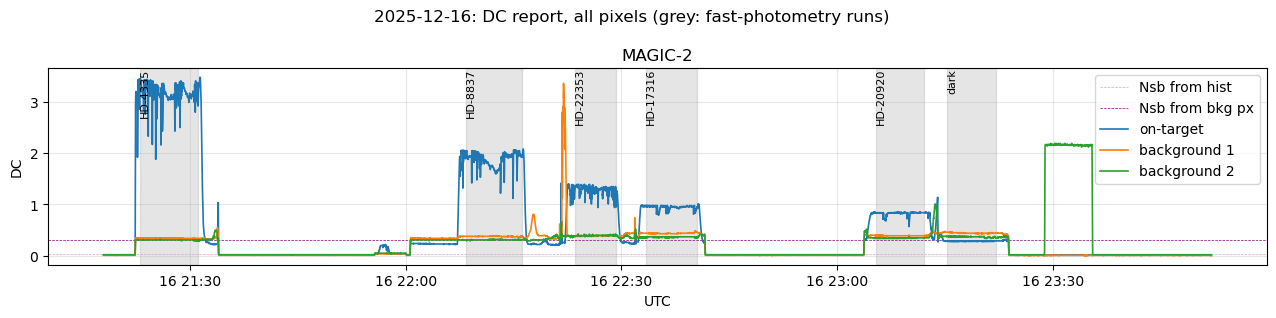

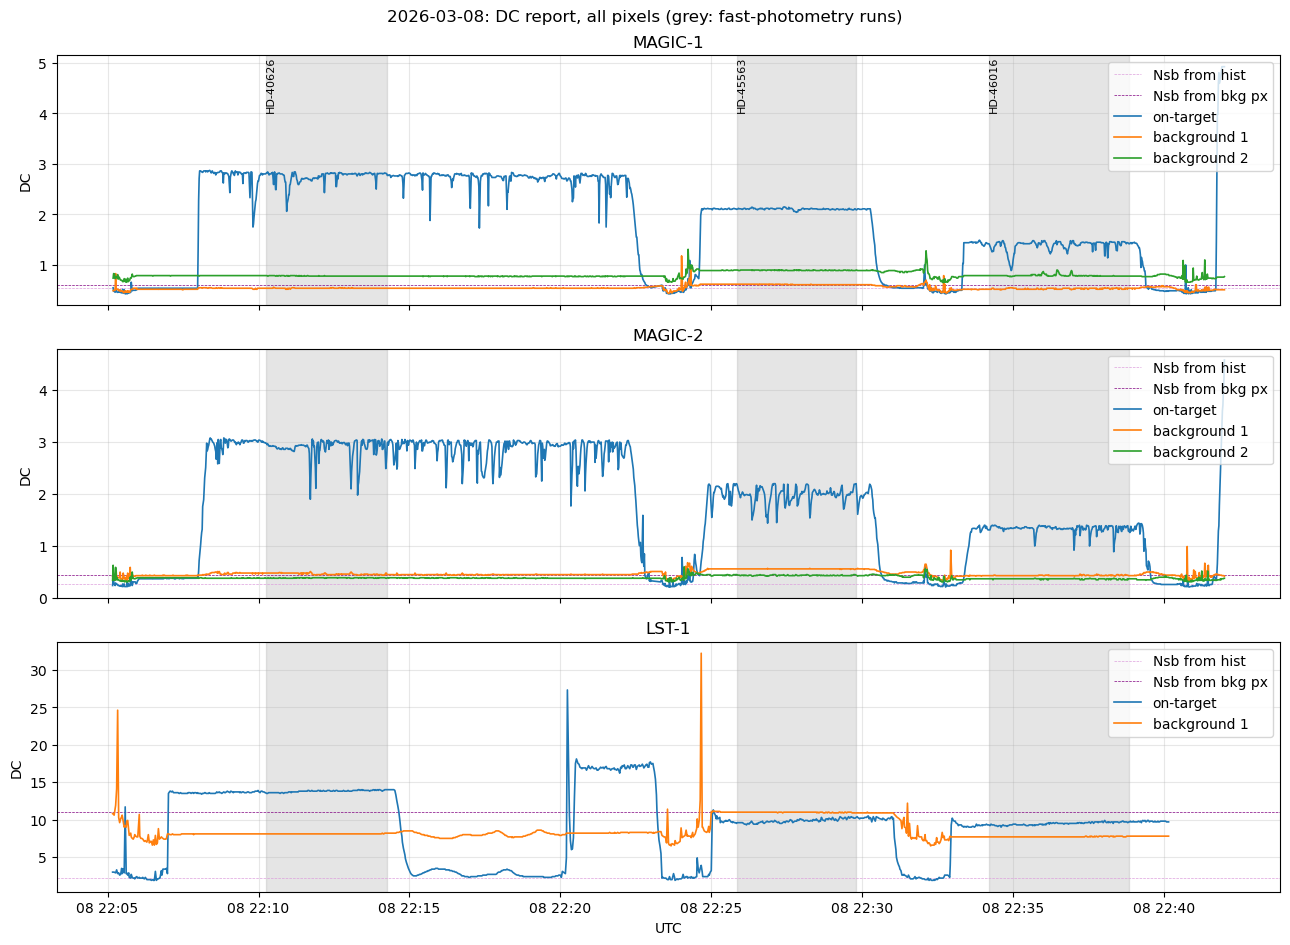

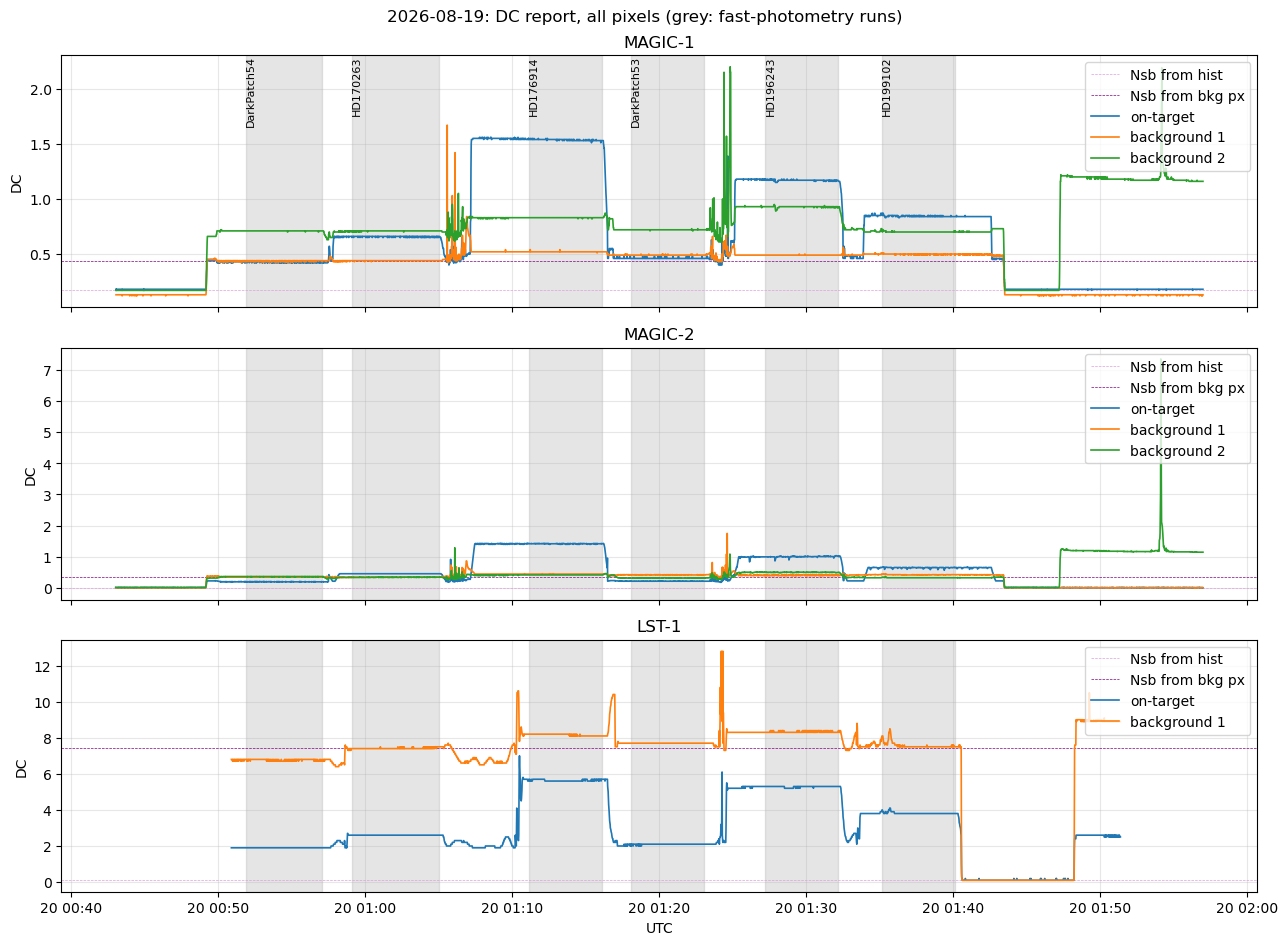

In [11]:
import pickle

PIXEL_LABELS = ["on-target", "background 1", "background 2"]   # columns of the report's `dcs` array

for night in NIGHTS:

    if not (night.dc_report and os.path.exists(night.dc_report)):
        continue
    with open(night.dc_report, "rb") as f:
        report = pickle.load(f)
    available = [tel for tel in config.ORM_ARRAY.telescopes if len(getattr(report, tel.dc_key)["times"]) > 0]
    spans = {o.name: o.time_span() for o in night.observations.values()}
    to_dt = lambda t: Time(t, format="unix").datetime
    fig, axes = plt.subplots(len(available), 1, squeeze=False, figsize=(13, 3.2 * len(available)), sharex=True)
    first = list(night.observations)[1]
    for ax, tel in zip(axes[:, 0], available):
        data = getattr(report, tel.dc_key)
        t_dc = Time(data["times"], format="isot", scale="utc").datetime

        nsb_hist = nsb['nsb_dc_hist'][night.name][first][tel.name]
        nsb_bkg = nsb['nsb_dc_bkg'][night.name][first][tel.name]
        ax.axhline(nsb_hist, linestyle='--', color='plum', lw = 0.5, label='Nsb from hist')
        ax.axhline(nsb_bkg, linestyle='--', color='purple', lw = 0.5, label='Nsb from bkg px')
        
        for p in range(data["dcs"].shape[1]):
            ax.plot(t_dc[:], data["dcs"][:, p], lw=1.2, label=PIXEL_LABELS[p])
            #ax.plot(t_dc[:-200], data["dcs"][:-200, p], lw=0.8, label=PIXEL_LABELS[p])
        for t0, t1 in spans.values():
            ax.axvspan(*to_dt([t0, t1]), color="grey", alpha=0.2)
        
        ax.set_ylabel("DC"); ax.grid(alpha=0.3, which="both")
        ax.set_title(tel.name, fontsize=12); ax.legend(fontsize=10, loc="upper right")
    for name, (t0, t1) in spans.items():
        axes[0, 0].text(to_dt(t0), axes[0, 0].get_ylim()[1], name, rotation=90, va="top", fontsize=8)
    axes[-1, 0].set_xlabel("UTC")
    fig.suptitle(f"{night.name}: DC report, all pixels (grey: fast-photometry runs)")
    fig.tight_layout()
    plt.show()

## 5. Measured SNR

All SNRs are at the binned cadence (`n_bin` samples per point) on the good-time window, with the default NSB of section 4.

| column | signal | noise | old notebook |
|---|---|---|---|
| `mean_fast` | mean of binned fast signal − NSB | ⟨per-bin std/√n⟩ ⊕ NSB error | method 1 |
| `peak_fast` | last histogram peak − NSB | same | method p1 |
| `mean_comb`, `peak_comb` | same on the fast+DC combined signal (DC units, NSB in DC units) | same | methods 2/3, p2/p3 |
| `mean_fast_dcnsb` | mean − NSB from the DC background pixel | same | method 3 |
| `detr` | baseline − NSB | robust bin-to-bin σ after removing a `DETREND_WINDOW_S` rolling baseline | (new) |
| `detr_full` | as `detr`, whole run instead of good-time window | | |
| `detr_despiked` | as `detr`, after dropping samples near DC excursions (wind/tracking dips) | | `remove_valleys_dc` |
| `detr_dcdetrend` | as `detr`, after dividing by the smoothed DC trend | | |

`mean_*`/`peak_*` only see scatter *within* a bin, so noise correlated over ≥ one bin is invisible to them and they run high (plus an ~8 % small-sample bias at n_bin=10). `detr` sees the bin-to-bin scatter, which is what a dip of that duration has to beat: **`detr` is the one to compare to theory.**

In [16]:
N_BINS = [10, 20, 200]
snr = measured_snr_table(log, n_bins=N_BINS, nsb=nsb, lcs=lcs)


In [17]:
snr

bin_ms nsb_source  dc_bad_frac  inband_rms  welch_short  mf_sigma  mean_fast  peak_fast  mean_fast_dcnsb     detr  detr_full  mean_comb  peak_comb  detr_despiked  detr_dcdetrend
night      observation telescope n_bin                                                                                                                                                                                    
2025-12-16 HD-4335     MAGIC-2   10       5.243       dark        0.081       0.003          0.0     0.080    462.826    480.373          497.148  199.932     98.039    465.322    481.968        201.766         210.255
                                 20      10.486       dark        0.081       0.003          0.0     0.080    598.425    621.113          657.759  225.945    101.937    602.161    623.702        218.374         242.701
                                 200    104.856       dark        0.081       0.003          0.0     0.080   1314.879   1364.767         1946.060  291.265    115.214   1333.903   1381.656        273.543         308.013
           HD-8837     MAGIC-2   10       5.243       dark        0.075       0.002          1.0     0.096    455.843    469.302          530.401  223.499    105.703    457.838    471.413        223.499         208.921
                                 20      10.486       dark        0.075       0.002          1.0     0.096    572.508    589.411          709.772  243.988    108.213    575.610    592.678        243.988         225.277
...                                         ...        ...          ...         ...          ...       ...        ...        ...              ...      ...        ...        ...        ...            ...             ...
2026-08-19 HD196243    MAGIC-1   20      10.486       dark        0.000       0.004          0.0     0.140    198.936    213.694          270.404   91.864    147.087    199.057    214.079         91.864          97.332
                                 200    104.856       dark        0.000       0.004          0.0     0.140    303.378    325.880          785.003  120.145    226.847    303.715    326.633        120.145         138.912
           HD199102    MAGIC-1   10       5.243       dark        0.000       0.002          0.0     0.072    132.793    142.599          200.040  110.801    103.650    134.411    144.922        110.801         102.214
                                 20      10.486       dark        0.000       0.002          0.0     0.072    149.643    160.694          266.046  129.033    119.922    151.590    163.444        129.033         119.438
                                 200    104.856       dark        0.000       0.002          0.0     0.072    180.206    193.513          782.057  195.248    179.302    182.864    197.162        195.248         181.146

[78 rows x 15 columns]

## 6. Theoretical SNR

`Instrument.realistic_signal_to_noise_ratio` at each observation's binning, for the star's B and V magnitude (the model normalises to Vega over the unfiltered QE band, so neither is exact; for these late-B stars B−V ≈ 0 and the difference is small):

- `theo_shot`: shot noise only (old optimistic model);
- `theo_zenith`: shot × F² + electronic + scintillation at the zenith;
- `theo_obs`: same at the observation's airmass (scintillation **and** extinction), times the fraction of mirror area left after the faulty panels listed in the log.

The faulty panels are the observation's own `faulty_mirrors` entry when the log has one, otherwise the night's value.

In [18]:
theory = theoretical_snr_table(snr, log, conditions)
results = snr.join(theory)
#results["ratio_detr_B"] = results["detr"] / results["theo_obs_B"]
results["ratio_peak_comb"] = results["peak_comb"] / results["theo_obs_B"]
results[["mean_fast","peak_comb", "theo_obs_B", "ratio_peak_comb", "airmass", "mirror_throughput"]]

mean_fast  peak_comb  theo_obs_B  ratio_peak_comb  airmass  mirror_throughput
night      observation telescope n_bin                                                                               
2025-12-16 HD-4335     MAGIC-2   10       462.826    481.968     778.067            0.619    1.075              0.996
                                 20       598.425    623.702    1100.353            0.567    1.075              0.996
                                 200     1314.879   1381.656    3479.622            0.397    1.075              0.996
           HD-8837     MAGIC-2   10       455.843    471.413     769.571            0.613    1.059              0.996
                                 20       572.508    592.678    1088.337            0.545    1.059              0.996
...                                           ...        ...         ...              ...      ...                ...
2026-08-19 HD196243    MAGIC-1   20       198.936    214.079    1043.662            0.205    1.070              0.955
                                 200      303.378    326.633    3300.349            0.099    1.070              0.955
           HD199102    MAGIC-1   10       132.793    144.922     708.021            0.205    1.054              0.955
                                 20       149.643    163.444    1001.292            0.163    1.054              0.955
                                 200      180.206    197.162    3166.365            0.062    1.054              0.955

[78 rows x 6 columns]

In [20]:
results

bin_ms nsb_source  dc_bad_frac  inband_rms  welch_short  mf_sigma  mean_fast  peak_fast  mean_fast_dcnsb     detr  detr_full  mean_comb  peak_comb  detr_despiked  detr_dcdetrend  airmass  mirror_throughput  \
night      observation telescope n_bin                                                                                                                                                                                                                   
2025-12-16 HD-4335     MAGIC-2   10       5.243       dark        0.081       0.003          0.0     0.080    462.826    480.373          497.148  199.932     98.039    465.322    481.968        201.766         210.255    1.075              0.996   
                                 20      10.486       dark        0.081       0.003          0.0     0.080    598.425    621.113          657.759  225.945    101.937    602.161    623.702        218.374         242.701    1.075              0.996   
                                 200    104.856       dark        0.081       0.003          0.0     0.080   1314.879   1364.767         1946.060  291.265    115.214   1333.903   1381.656        273.543         308.013    1.075              0.996   
           HD-8837     MAGIC-2   10       5.243       dark        0.075       0.002          1.0     0.096    455.843    469.302          530.401  223.499    105.703    457.838    471.413        223.499         208.921    1.059              0.996   
                                 20      10.486       dark        0.075       0.002          1.0     0.096    572.508    589.411          709.772  243.988    108.213    575.610    592.678        243.988         225.277    1.059              0.996   
...                                         ...        ...          ...         ...          ...       ...        ...        ...              ...      ...        ...        ...        ...            ...             ...      ...                ...   
2026-08-19 HD196243    MAGIC-1   20      10.486       dark        0.000       0.004          0.0     0.140    198.936    213.694          270.404   91.864    147.087    199.057    214.079         91.864          97.332    1.070              0.955   
                                 200    104.856       dark        0.000       0.004          0.0     0.140    303.378    325.880          785.003  120.145    226.847    303.715    326.633        120.145         138.912    1.070              0.955   
           HD199102    MAGIC-1   10       5.243       dark        0.000       0.002          0.0     0.072    132.793    142.599          200.040  110.801    103.650    134.411    144.922        110.801         102.214    1.054              0.955   
                                 20      10.486       dark        0.000       0.002          0.0     0.072    149.643    160.694          266.046  129.033    119.922    151.590    163.444        129.033         119.438    1.054              0.955   
                                 200    104.856       dark        0.000       0.002          0.0     0.072    180.206    193.513          782.057  195.248    179.302    182.864    197.162        195.248         181.146    1.054              0.955   

                                        theo_shot_B  theo_zenith_B  theo_obs_B  theo_shot_V  theo_zenith_V  theo_obs_V  ratio_peak_comb  
night      observation telescope n_bin                                                                                                   
2025-12-16 HD-4335     MAGIC-2   10        5076.681        781.823     778.067     4912.503        780.991     777.220            0.619  
                                 20        7179.511       1105.664    1100.353     6947.328       1104.488    1099.155            0.567  
                                 200      22703.609       3496.418    3479.622    21969.381       3492.698    3475.835            0.397  
           HD-8837     MAGIC-2   10        3825.939        772.659     769.571     3764.537        7

## 7. Measured vs theoretical SNR

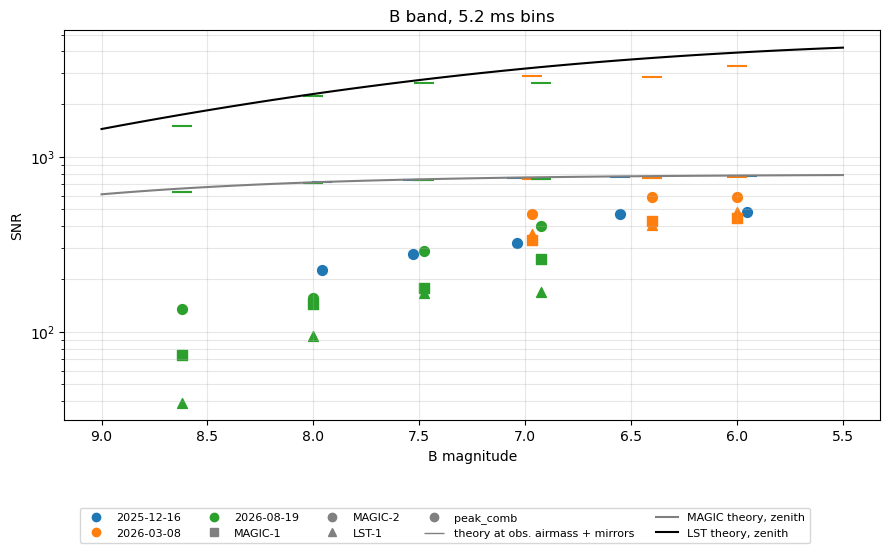

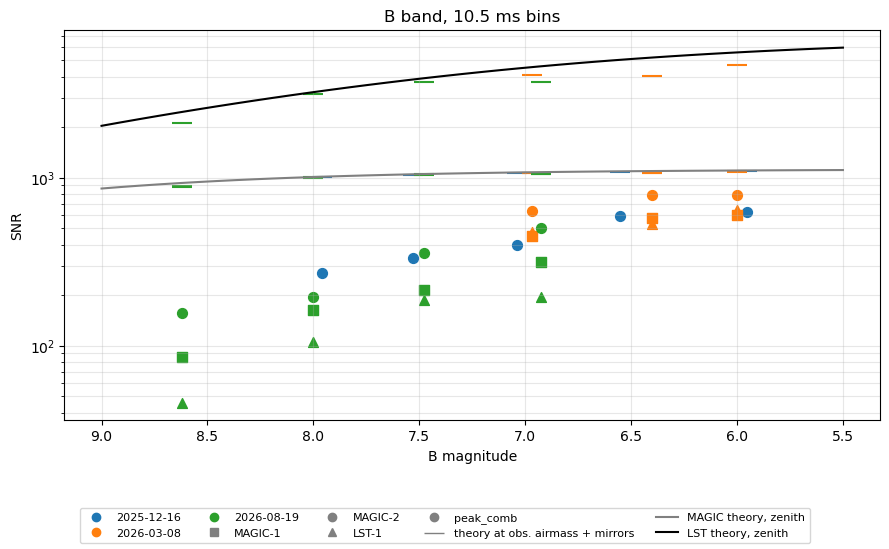

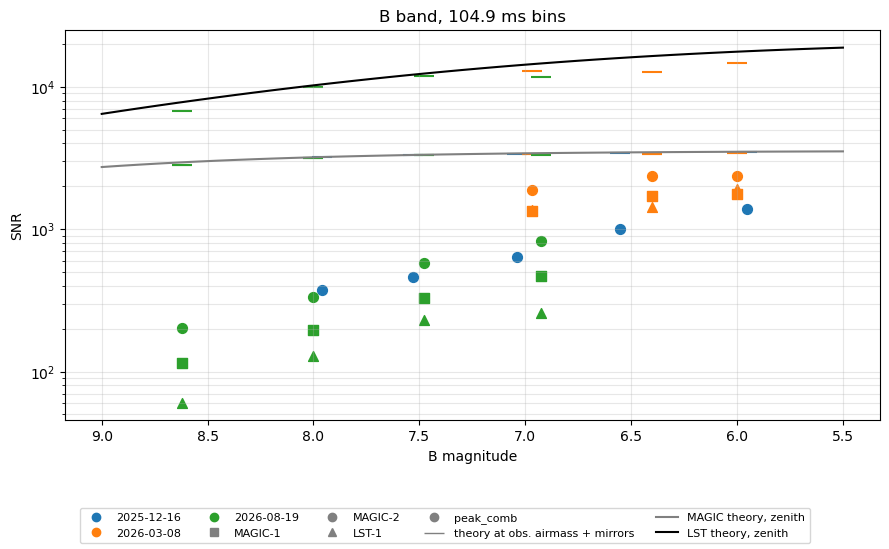

In [19]:
for n in N_BINS:
    plot_snr_vs_magnitude(results, log, n, ("peak_comb"))
    plt.show()

### Which approach moves the measurement closest to theory?
Median measured/theory (`theo_obs_B`) per night, telescope and approach:

In [26]:
approaches = ["mean_fast", "peak_fast", "mean_comb", "peak_comb", "mean_fast_dcnsb", "detr", "detr_full",
              "detr_despiked", "detr_dcdetrend"]
ratios = results[approaches].div(results["theo_obs_B"], axis=0)
ratios.groupby(level=["night", "telescope", "n_bin"]).median()

mean_fast  peak_fast  mean_comb  peak_comb  mean_fast_dcnsb   detr  detr_full  detr_despiked  detr_dcdetrend  detr_ext
night      telescope n_bin                                                                                                                        
2025-12-16 MAGIC-2   10         0.139      0.145      0.171      0.179            0.173  0.076      0.037          0.076           0.060     0.076
                     200        0.057      0.059      0.154      0.161            0.157  0.020      0.010          0.020           0.017     0.021
2026-03-08 LST-1     10         0.105      0.112      0.104      0.111            0.025  0.029      0.030          0.029           0.030     0.030
                     200        0.085      0.094      0.085      0.088            0.021  0.009      0.009          0.009           0.009     0.009
           MAGIC-1   10         0.147      0.151      0.147      0.151            0.147  0.061      0.053          0.067           0.061     0.063
                     200        0.129      0.132      0.130      0.134            0.129  0.017      0.015          0.019           0.017     0.017
           MAGIC-2   10         0.197      0.211      0.197      0.208            0.197  0.044      0.036          0.044           0.038     0.046
                     200        0.177      0.190      0.178      0.187            0.177  0.010      0.008          0.010           0.008     0.011
2026-08-19 LST-1     10         0.034      0.049      0.041      0.052           -0.072  0.020      0.020          0.020           0.019     0.021
                     200        0.013      0.017      0.034      0.043           -0.060  0.008      0.008          0.008           0.007     0.008
           MAGIC-1   10         0.089      0.097      0.114      0.127            0.122  0.066      0.066          0.066           0.064     0.067
                     200        0.031      0.034      0.099      0.111            0.107  0.025      0.025          0.025           0.024     0.026
           MAGIC-2   10         0.123      0.137      0.147      0.161            0.112  0.060      0.060          0.060           0.057     0.062
                     200        0.052      0.060      0.129      0.142            0.098  0.017      0.017          0.017           0.016     0.018

### Disparity vs observing conditions
Ratio of the detrended SNR to `theo_obs_B` (5 ms bins) against each candidate cause. A clear trend points at a cause the model does not include (or includes wrongly).

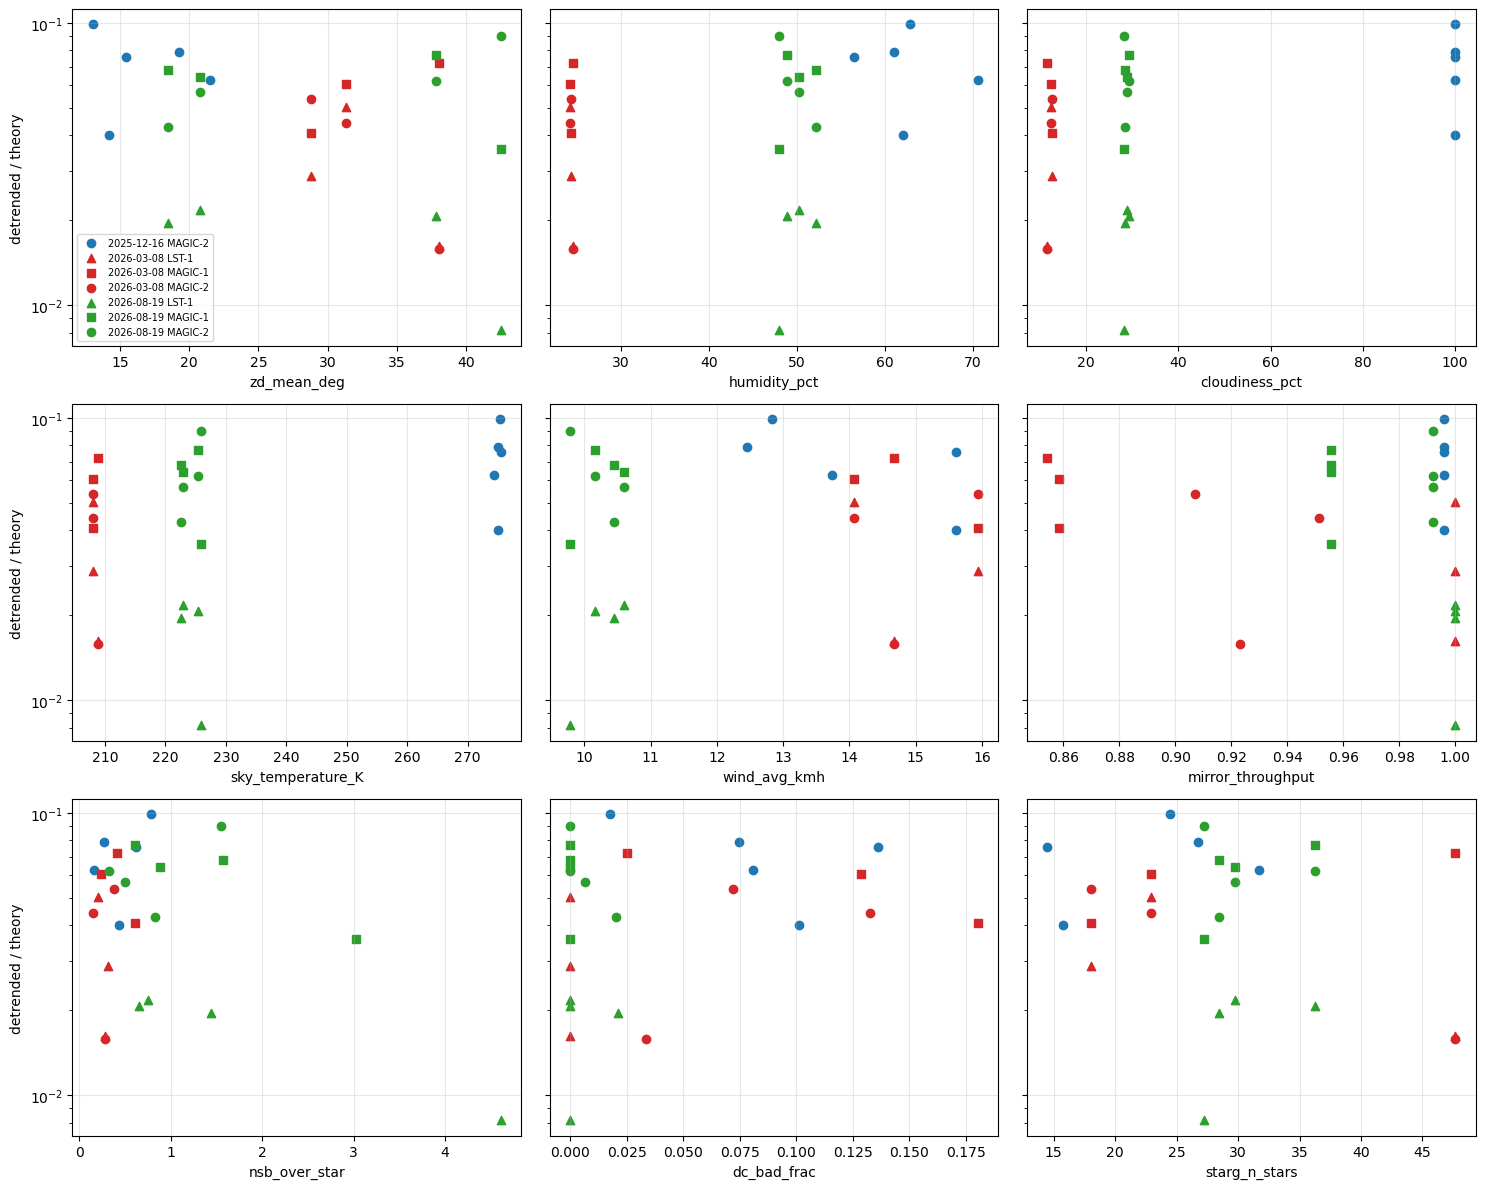

In [27]:
n = N_BINS[0]
df = results.xs(n, level="n_bin").reset_index().merge(conditions.reset_index(), on=["night", "observation"])
df = df.merge(nsb.reset_index()[["night", "observation", "telescope", "nsb_default", "star_mean"]],
              on=["night", "observation", "telescope"])
df["nsb_over_star"] = df["nsb_default"] / (df["star_mean"] - df["nsb_default"])
candidates = ["zd_mean_deg", "humidity_pct", "cloudiness_pct", "sky_temperature_K", "wind_avg_kmh",
              "mirror_throughput", "nsb_over_star", "dc_bad_frac", "starg_n_stars"]
fig, axes = plt.subplots(3, 3, figsize=(15, 12), sharey=True)
for ax, col in zip(axes.flat, candidates):
    for (night_name, tel_name), g in df.groupby(["night", "telescope"]):
        if col in g:
            ax.scatter(g[col], g["ratio_detr_B"], color=NIGHT_COLORS[night_name], marker=MARKERS[tel_name],
                       label=f"{night_name} {tel_name}")
    ax.set_xlabel(col); ax.set_yscale("log"); ax.grid(alpha=0.3)
axes[0, 0].set_ylabel("detrended / theory"); axes[1, 0].set_ylabel("detrended / theory"); axes[2, 0].set_ylabel("detrended / theory")
axes[0, 0].legend(fontsize=7)
fig.tight_layout()
plt.show()

## 8. Noise diagnostics

Fractional noise vs bin size, within-bin (open) and bin-to-bin after detrending (filled), against the white-noise 1/√n expectation (dashed, anchored at the smallest bin). Where the filled curve flattens away from the dashed line, correlated noise dominates and extra averaging stops helping. The good-time windows are short (30–60 s) for 2025-12-16 and 2026-03-08, so the whole run is used here. Below: band-limited RMS of the fractional flux from the PSD (the old notebook's band-RMS cells).

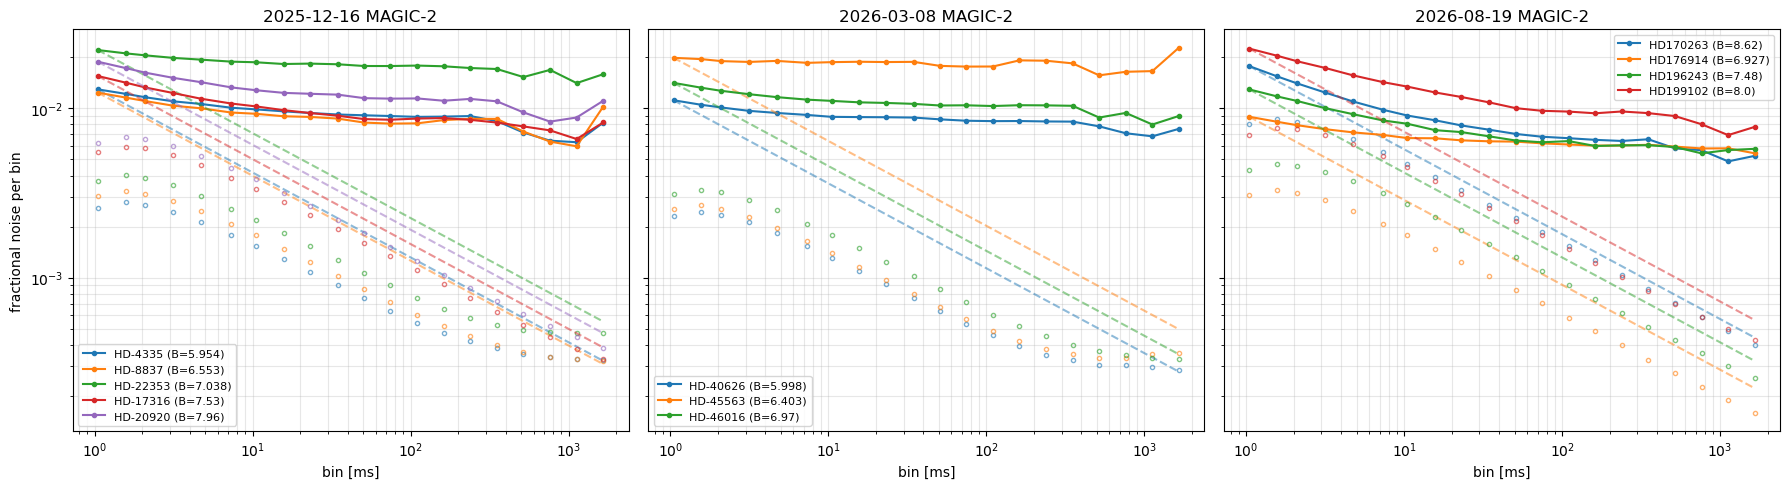

In [28]:
bin_sizes = np.unique(np.round(np.logspace(np.log10(2), 3.5, 20)).astype(int))
fig, axes = plt.subplots(1, len(NIGHTS), figsize=(6 * len(NIGHTS), 5), sharey=True, squeeze=False)
axes = axes[0]
for ax, night in zip(axes, NIGHTS):
    for obs in night.stars.values():
        lc = lcs[(night.name, obs.name, "A")]
        nsb0 = nsb.loc[(night.name, obs.name, "MAGIC-2"), "nsb_default_fast"]
        n_used, within, between = noise_vs_bin_size(lc, bin_sizes, nsb0, DETREND_WINDOW_S)
        bin_ms = n_used * lc.dt * 1e3
        line, = ax.loglog(bin_ms, between, "o-", ms=3, label=f"{obs.name} (B={obs.mag_B})")
        ax.loglog(bin_ms, within, "o", ms=3, mfc="none", color=line.get_color(), alpha=0.6)
        ax.loglog(bin_ms, between[0] / np.sqrt(n_used / n_used[0]), ls="--", color=line.get_color(), alpha=0.5)
    ax.set_title(f"{night.name} MAGIC-2"); ax.set_xlabel("bin [ms]"); ax.grid(alpha=0.3, which="both")
    ax.legend(fontsize=8)
axes[0].set_ylabel("fractional noise per bin")
fig.tight_layout()
plt.show()

In [29]:
PSD_BANDS = {"0.1-1 Hz": (0.1, 1), "1-10 Hz": (1, 10), "10-100 Hz": (10, 100), "100-900 Hz": (100, 900)}
psd_rows = []
for night in NIGHTS:
    for ch in night.channels:
        for obs in night.observations.values():
            lc = lcs[(night.name, obs.name, ch)]
            psd_rows.append({"night": night.name, "observation": obs.name, "telescope": TELESCOPES[ch].name,
                             **band_noise_rms(lc, PSD_BANDS, nperseg=2**14)})
pd.DataFrame(psd_rows).set_index(["night", "observation", "telescope"])

0.1-1 Hz  1-10 Hz  10-100 Hz  100-900 Hz
night      observation telescope                                          
2025-12-16 HD-4335     MAGIC-2       0.038    0.006      0.003       0.006
           HD-8837     MAGIC-2       0.030    0.005      0.003       0.006
           HD-22353    MAGIC-2       0.036    0.005      0.003       0.007
           HD-17316    MAGIC-2       0.014    0.002      0.004       0.009
           HD-20920    MAGIC-2       0.014    0.003      0.005       0.010
           dark        MAGIC-2       0.005    0.002      0.005       0.012
2026-03-08 HD-40626    MAGIC-2       0.037    0.004      0.002       0.005
           HD-45563    MAGIC-2       0.040    0.005      0.002       0.005
           HD-46016    MAGIC-2       0.028    0.004      0.002       0.006
           HD-40626    LST-1         0.004    0.003      0.004       0.007
           HD-45563    LST-1         0.011    0.004      0.005       0.008
           HD-46016    LST-1         0.008    0.003      0.004       0.008
           HD-40626    MAGIC-1       0.016    0.002      0.002       0.005
           HD-45563    MAGIC-1       0.003    0.001      0.002       0.005
           HD-46016    MAGIC-1       0.021    0.002      0.003       0.007
2026-08-19 DarkPatch54 MAGIC-2       0.003    0.002      0.005       0.011
           HD170263    MAGIC-2       0.003    0.001      0.004       0.008
           HD176914    MAGIC-2       0.004    0.001      0.003       0.006
           DarkPatch53 MAGIC-2       0.004    0.003      0.008       0.014
           HD196243    MAGIC-2       0.008    0.002      0.004       0.008
           HD199102    MAGIC-2       0.011    0.002      0.005       0.011
           DarkPatch54 LST-1         0.012    0.006      0.013       0.020
           HD170263    LST-1         0.012    0.006      0.010       0.021
           HD176914    LST-1         0.007    0.007      0.012       0.015
           DarkPatch53 LST-1         0.011    0.006      0.009       0.018
           HD196243    LST-1         0.007    0.004      0.008       0.012
           HD199102    LST-1         0.008    0.005      0.009       0.017
           DarkPatch54 MAGIC-1       0.004    0.003      0.007       0.013
           HD170263    MAGIC-1       0.005    0.003      0.007       0.012
           HD176914    MAGIC-1       0.002    0.001      0.003       0.006
           DarkPatch53 MAGIC-1       0.008    0.003      0.009       0.015
           HD196243    MAGIC-1       0.003    0.002      0.004       0.008
           HD199102    MAGIC-1       0.002    0.001      0.003       0.007

### How much of the noise does the detrend window remove?
Detrended SNR (5 ms bins, good-time window) for several baseline windows. A strong dependence means the noise lives at frequencies around 1/window, i.e. it is slow variability rather than per-sample noise.

In [30]:
windows_s = [0.5, 2.0, 10.0, 30.0]
win_rows = []
for night in NIGHTS:
    for ch in night.channels:
        for obs in night.stars.values():
            lc = good_time_lightcurve(lcs[(night.name, obs.name, ch)], obs.good_time)
            nsb0 = nsb.loc[(night.name, obs.name, TELESCOPES[ch].name), "nsb_default_fast"]
            win_rows.append({"night": night.name, "observation": obs.name, "telescope": TELESCOPES[ch].name,
                             **{f"detr_{w:g}s": detrended_snr(lc, N_BINS[0], nsb0, w)["snr"] for w in windows_s}})
pd.DataFrame(win_rows).set_index(["night", "observation", "telescope"])

detr_0.5s  detr_2s  detr_10s  detr_30s
night      observation telescope                                        
2025-12-16 HD-4335     MAGIC-2      302.238  281.738   213.982   109.439
           HD-8837     MAGIC-2      345.469  311.965   223.499   105.354
           HD-22353    MAGIC-2      207.484  170.798    96.223    89.549
           HD-17316    MAGIC-2      267.391  253.502   146.769    90.042
           HD-20920    MAGIC-2      216.276  199.708   157.709    96.919
2026-03-08 HD-40626    MAGIC-2      406.646  296.419   138.084   113.450
           HD-45563    MAGIC-2      374.181  252.282    41.348    40.584
           HD-46016    MAGIC-2      322.126  261.350   121.630    89.458
           HD-40626    LST-1        298.513  277.272   217.255   139.542
           HD-45563    LST-1        156.582  134.629    60.005    35.488
           HD-46016    LST-1        160.729  154.192    98.767    36.496
           HD-40626    MAGIC-1      332.253  284.704   185.106   123.114
           HD-45563    MAGIC-1      287.891  273.609   182.634   158.240
           HD-46016    MAGIC-1      227.819  197.362    90.454    16.301
2026-08-19 HD170263    MAGIC-2      124.739  121.439    93.856    74.245
           HD176914    MAGIC-2      309.334  288.567   140.744   132.068
           HD196243    MAGIC-2      183.523  172.768   111.033    85.957
           HD199102    MAGIC-2      130.922  122.004    66.381    45.172
           HD170263    LST-1         17.322   16.123    13.212     6.450
           HD176914    LST-1         85.992   80.932    67.180    41.126
           HD196243    LST-1         78.554   75.061    64.760    41.637
           HD199102    LST-1         61.195   58.537    46.823    31.452
           HD170263    MAGIC-1       55.911   53.149    36.858    27.298
           HD176914    MAGIC-1      241.961  234.184   170.401   174.009
           HD196243    MAGIC-1      159.745  153.276   123.708    89.218
           HD199102    MAGIC-1      136.093  130.553   103.650    76.662

### Per-frame noise floor
Sample-to-sample scatter of the raw 0.5 ms frames (`frame_noise`: differencing removes everything slower than ~1 ms) against the signal level, for stars and dark runs. Each frame's flux proxy is a variance estimated from 2¹⁸ digitizations, which has a relative error of √(2k/2¹⁸) (k = correlated consecutive samples) **independent of the star brightness**. The photon-counting noise model does not include it. A fit σ² = a² + b²/level per telescope separates a level-independent floor `a` from a term that falls with the signal level, like shot noise.

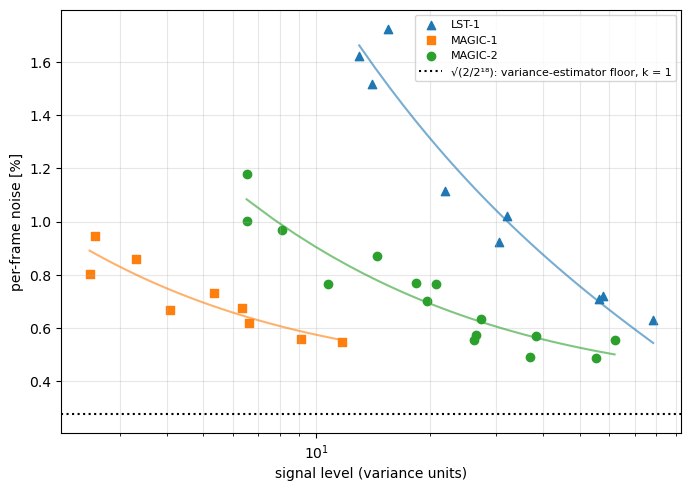

,floor_a_pct,b,k_equivalent
LST-1,0.000,0.062,0.000
MAGIC-1,0.418,0.012,2.292
MAGIC-2,0.376,0.026,1.850


In [31]:
fr_rows = []
for night in NIGHTS:
    for ch in night.channels:
        for obs in night.observations.values():
            lc = lcs[(night.name, obs.name, ch)]
            fr_rows.append({"night": night.name, "observation": obs.name, "telescope": TELESCOPES[ch].name,
                            "type": obs.type, "level": float(np.median(lc.signal)), "frame_noise": frame_noise(lc)})
frames = pd.DataFrame(fr_rows)
floor_k1 = variance_estimator_floor(config.standard_sampling)

fig, ax = plt.subplots(figsize=(8, 5.5))
fits = {}
for tel_name, g in frames.groupby("telescope"):
    b2, a2 = np.polyfit(1.0 / g["level"], g["frame_noise"] ** 2, 1)
    fits[tel_name] = {"floor_a_pct": 100 * np.sqrt(max(a2, 0)), "b": np.sqrt(max(b2, 0)),
                      "k_equivalent": max(a2, 0) / floor_k1 ** 2}
    pts = ax.scatter(g["level"], 100 * g["frame_noise"], marker=MARKERS[tel_name], label=tel_name)
    lv = np.linspace(g["level"].min(), g["level"].max(), 50)
    ax.plot(lv, 100 * np.sqrt(np.maximum(a2 + b2 / lv, 0)), color=pts.get_facecolor()[0], alpha=0.6)
ax.axhline(100 * floor_k1, color="k", ls=":", label="√(2/2¹⁸): variance-estimator floor, k = 1")
ax.set_xscale("log"); ax.set_xlabel("signal level (variance units)"); ax.set_ylabel("per-frame noise [%]")
ax.legend(fontsize=8); ax.grid(alpha=0.3, which="both")
plt.show()
pd.DataFrame(fits).T

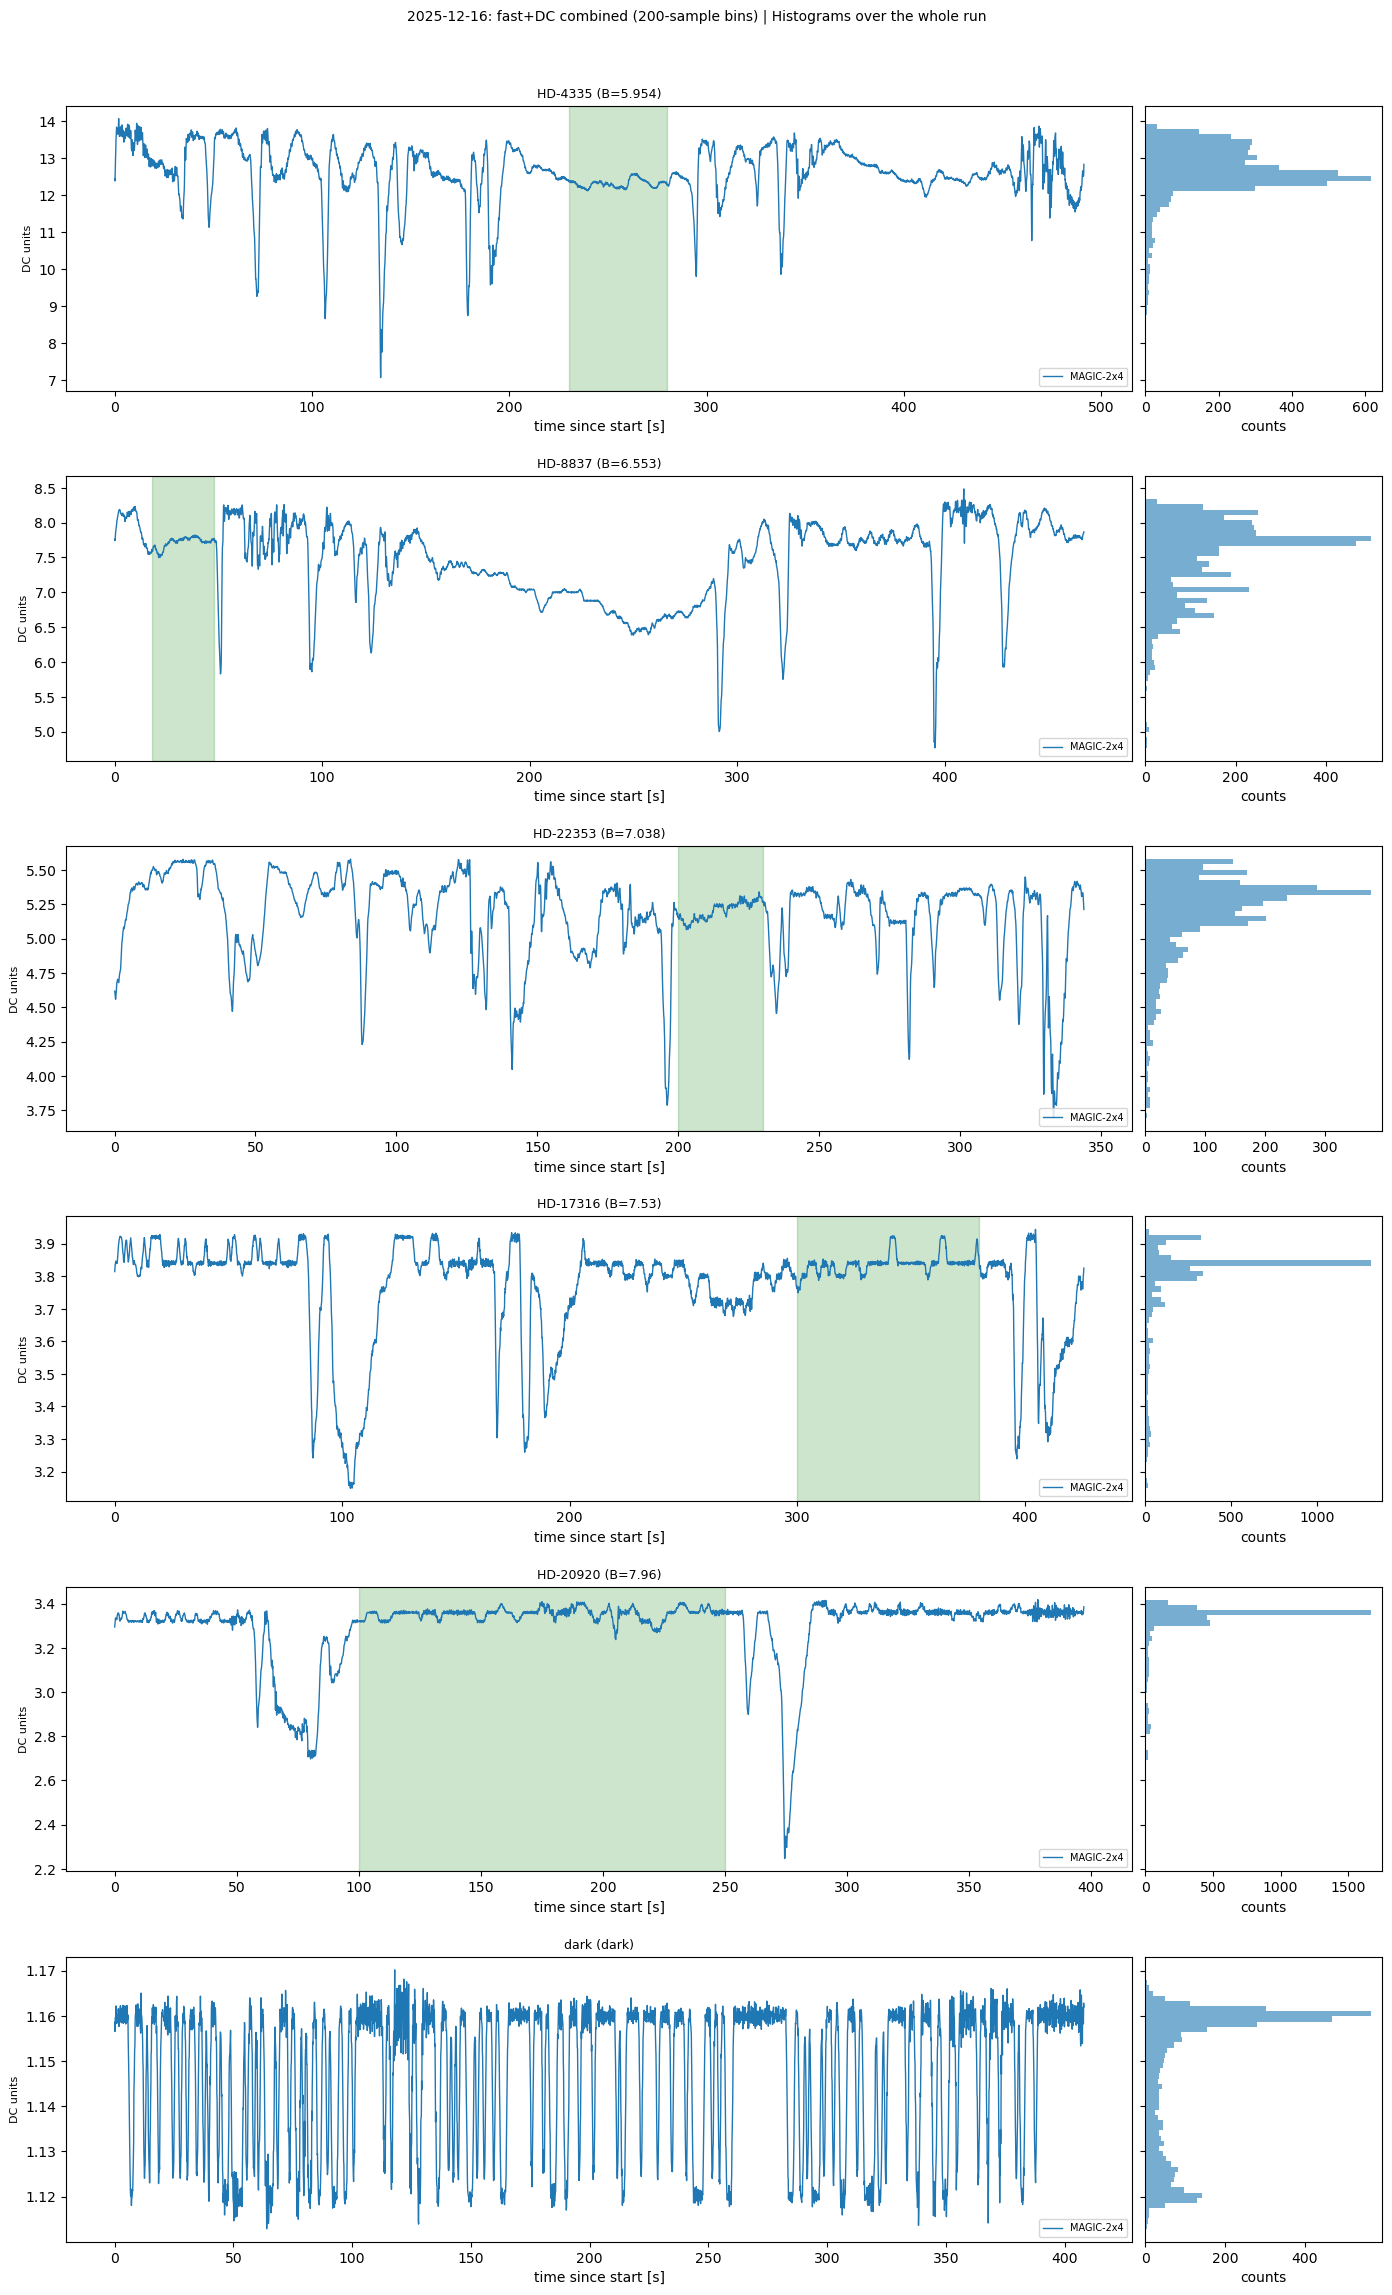

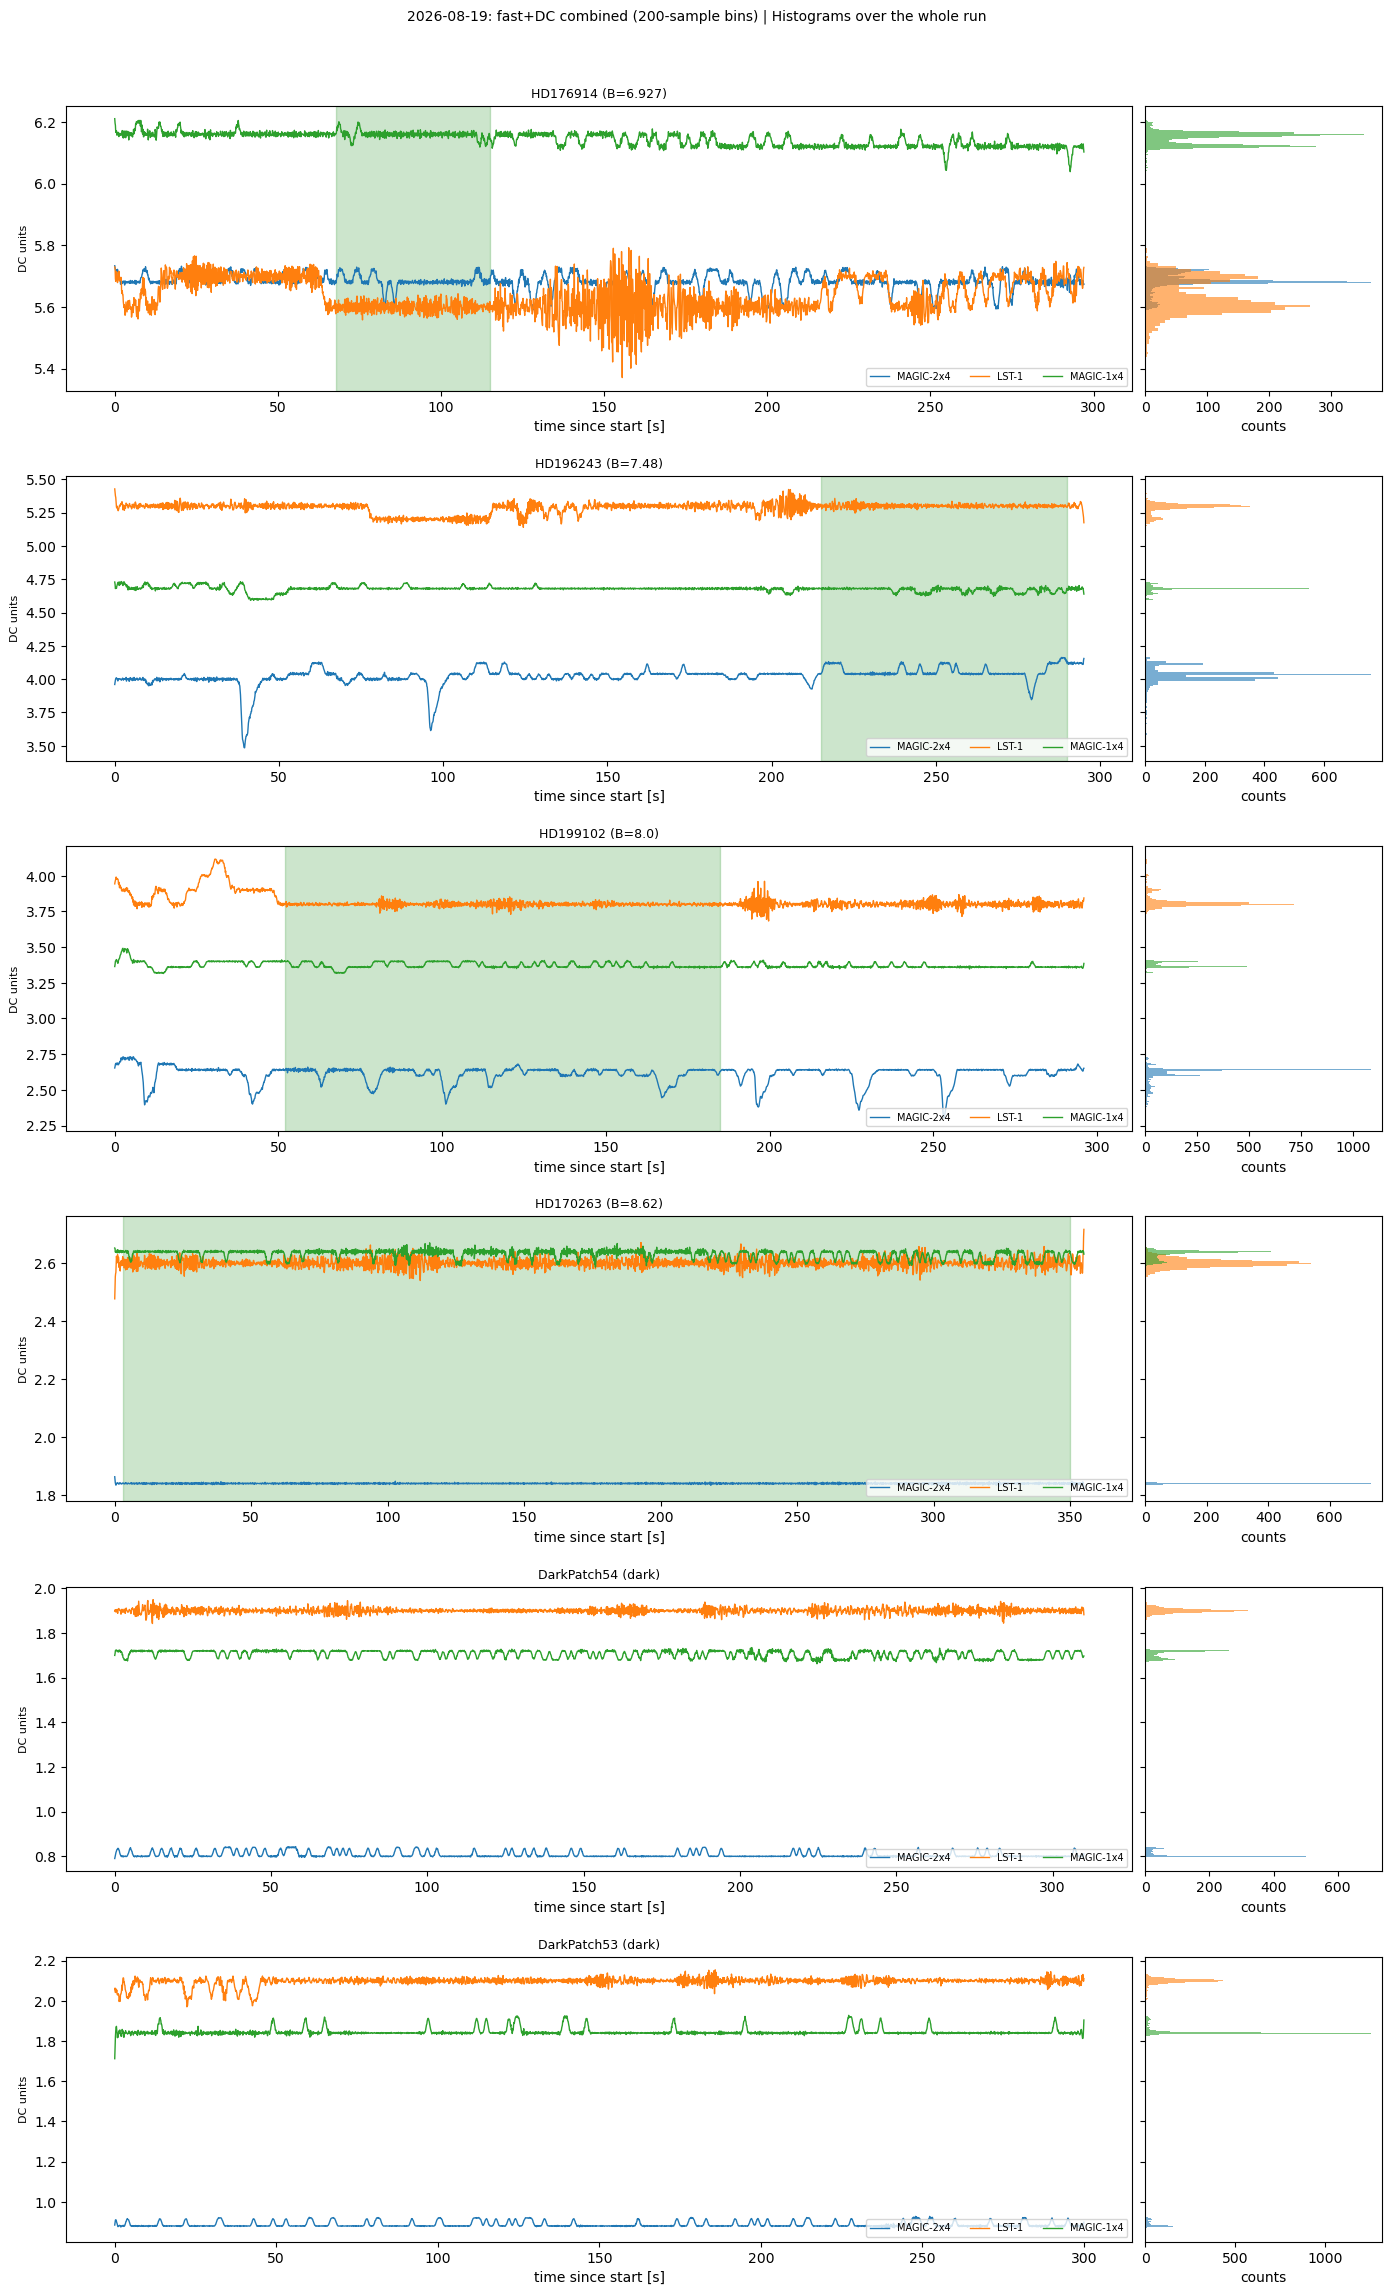

In [ ]:
# Cell to plot the lightcurves of combined fast and DC signal all together. The three telescopes in one plot, with the MAGIC signals scaled
HIST_GOOD_TIME_ONLY = False   # True: histograms use only the good-time window
HIST_BINS = 50

for night in NIGHTS:
    dc = night_dc(night)
    if not dc:
        continue
    n_obs = len(night.observations)
    fig = plt.figure(figsize=(14, 4.0 * n_obs))
    gs = fig.add_gridspec(n_obs, 2, width_ratios=[4.5, 1], wspace=0.02, hspace=0.3)

    for i, obs in enumerate(plot_order(night)):
        label = f"B={obs.mag_B}" if obs.is_star else obs.type
        ax = fig.add_subplot(gs[i, 0])
        hax = fig.add_subplot(gs[i, 1], sharey=ax)
        hax.tick_params(labelleft=False)
        ax.set_title(f"{obs.name} ({label})", fontsize=9)
        ax.set_ylabel("DC units", fontsize=8)
        ax.set_xlabel("time since start [s]")
        hax.set_xlabel("counts")

        if obs.good_time:
            ax.axvspan(*obs.good_time, color="green", alpha=0.2)

        for j, ch in enumerate(night.channels):
            color = f"C{j}"
            lc = lcs[(night.name, obs.name, ch)]
            dc_key = TELESCOPES[ch].dc_key
            try:
                comb = combine_lightcurve_with_dc(lc, night.dc_report, DC_CUT_HZ[dc_key], telescope=dc_key)
            except (ValueError, KeyError):   # no DC for this telescope, or DC doesn't cover the run
                continue
            t, s, _ = bin_average(comb.time - lc.time[0], comb.signal, N_BINS[1])
            if ch != 'B': # So that MAGIC and LST are closer together
                s *= 4.0
                ax.plot(t, s, lw=0.99, color=color, label=TELESCOPES[ch].name + 'x4')
            else:
                ax.plot(t, s, lw=0.99, color=color, label=TELESCOPES[ch].name)
            in_hist = (t >= obs.good_time[0]) & (t <= obs.good_time[1]) if HIST_GOOD_TIME_ONLY and obs.good_time else slice(None)
            hax.hist(s[in_hist], bins=HIST_BINS, orientation="horizontal",
                     color=color, alpha=0.6)

        ax.legend(fontsize=7, loc="lower right", ncol=len(night.channels))

    hist_range = "good-time window" if HIST_GOOD_TIME_ONLY else "whole run"
    fig.suptitle(f"{night.name}: fast+DC combined ({N_BINS[1]}-sample bins) | "
                 f"Histograms over the {hist_range}", fontsize=10)
    fig.subplots_adjust(left=0.05, right=0.99, top=0.94, bottom=0.05)
    plt.show()

## 9. Sources of disparity: checklist

Evidence gathered above (✔ = checked in this notebook, ☐ = still to check / needs information you have to add to the log).

**Measurement side**
- ✔ *Estimator choice.* `mean_*`/`peak_*` ignore correlated noise and run ~8 % high from the small-sample bias at 5 ms; the detrended estimator is the fair one (section 5). Its value depends on the detrend window (table in section 8).
- ✔ *Slow drifts* (transparency, tracking, wind): compare `detr_full` vs `detr` and `detr_despiked`/`detr_dcdetrend` (section 7 table); `dc_bad_frac` gives the fraction of each run flagged by DC excursions.
- ✔ *NSB subtraction.* 2026-03-08 has no dark run, so its NSB comes from the DC, converted with the fast/DC ratio, which ignores the electronic pedestal of the variance (section 4). Cross-check: LST-1's DC-histogram NSB on 2026-03-08 (≈13.1–13.6 fast units) agrees with the 2026-08-19 LST-1 dark patch (13.0). The LST-1 background pixel reads far too high (`mean_fast_dcnsb` goes negative), so use `dc_hist` for LST-1, but only when the DC history has no camera-off periods. On 2026-08-19 its first peak is the closed-camera level (≈0.8 fast units vs 13.0 from the dark patch). 2026-08-19 uses its dark patches.
- ☐ *Good-time windows* for 2026-08-19 are not set (whole runs used).
- ✔ *Correlated (red) noise.* This is the dominant effect. After a 10 s detrend, the bin-to-bin noise is nearly flat at ~1 % from 1 ms to 1 s (section 8); the PSD puts 1–4 % RMS in 0.1–1 Hz against ≲0.5 % in 1–10 Hz. Averaging therefore stops helping after a few ms, and the 100 ms ratios are far worse than the 5 ms ones. Candidate causes: wind-driven structure or mirror vibrations moving the star image across the 0.1° pixel, tracking jitter, and scintillation larger than the Young model.
- ✔ *Per-frame floor.* Even at 0.5 ms the MAGIC scatter has a level-independent floor of ≈0.4 % (fit: 0.38 % for MAGIC-2, 0.42 % for MAGIC-1, i.e. ≈1.4–1.5× √(2/2¹⁸), k ≈ 2). That is consistent with the statistical error of the per-frame variance estimate with ~2 correlated digitizer samples, and it is not in `noise_budget`. LST-1 shows no such floor: its per-frame scatter is level-dependent. ☐ Measuring the digitizer autocorrelation (k) would turn this into a model term.

**Atmosphere**
- ✔ *Extinction at the real Zd* is now in `theo_obs`. Old `zd_dict` values were wrong for 2026-03-08 (HD-40626 31.3° not 38°, HD-46016 28.8° not 30°).
- ✔ *Clouds.* **2025-12-16: the pyrometer reads 100 % cloudiness all night, with a sky temperature ≈ air temperature (~275 K, vs ~208 K on the clear 2026-03-08).** That is the signature of an overcast sky, or of a covered/faulty pyrometer. Yet the MAGIC-2 starguider identifies 15–32 stars during the runs (fewer than the 18–48 of 2026-03-08), and the measured/theory ratio is not lower that night. Thin or broken cloud, or a pyrometer problem, are both possible. ☐ Check the eLog.
- ✔ *Humidity/wind* (section 2): 2025-12-16 ~55–70 % RH, 2026-03-08 ~25 % RH.
- ☐ *LIDAR:* not operating on any night (ERROR_CODE 4), so there is no measured transmission.
- ✔ *Moon:* below the horizon for all star runs (`moon_alt_deg`).
- ☐ *Scintillation:* the model uses Young's formula with `scint_coeff=1`; La Palma studies suggest ~1.5.

**Telescope**
- ✔ *Faulty mirrors:* 2026-03-08 AMC `PANELS[1]` grows from 7 to 18 on MAGIC-2 during the three runs. ☐ Confirm what the four AMC `PANELS` counts mean, and the panel totals in `snr_measurement.N_PANELS`; only the YAML panel lists enter `theo_obs` for now.
- ☐ *Faulty mirrors 2025-12-16 / 2026-08-19 and LST-1:* unknown.
- ☐ *Star centring in the pixel / PSF:* the starguider pointing deviation (`starg_dev_rms_deg`) is in the conditions table; a star off the pixel centre loses light.
- ☐ *Pixel gain/HV and the PMT excess-noise factor* (model: F = 1.15, 0.7 p.e. electronic noise).

**Model side**
- ✔ *Band:* B and V both plotted; the model's Vega normalisation over the unfiltered QE band is neither.
- ☐ *MAGIC optics* use the LST QE/reflectivity files (see `magic-is-scaled-lst-optics`), so only the area differs.